# Nuclei-segmentation benchmark and its impact on downstream analysis 
### DAPI / CK / CD8 multiplex immunofluorescence - Watershed vs StarDist vs Cellpose

**Question.** Does the choice of nuclei-segmentation method change the quantities we feed into the
survival analysis (CD8+ cell density), and does it change the survival conclusions?

## 1. Setup and configuration

In [1]:
import os, glob, json, time, pickle, hashlib, warnings, itertools, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import io, filters, morphology, measure
from skimage.feature import peak_local_max
from skimage.segmentation import find_boundaries, expand_labels, relabel_sequential
from skimage.segmentation import watershed as sk_watershed

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------------ paths
DATA_DIR       = "./Data/DAPI_PanCK_CD8"
CLINICAL_CSV   = "./Data/samples_clinical_merged.csv"
PATIENT_ID_COL = "ID"     # several cores belong to one patient: cores are pooled per patient (Section 7)
KNOWN_ARTIFACT_CORES = ['Core[1,8,G]', 'Core[1,8,H]']   # the two cores with uneven illumination
INCLUDE_ARTIFACT_CORES = False  # True = include them in the cohort statistics. Default False: see Section 3.2.
                                # They are always segmented and shown as a stress test (Section 6).
DEMO_CORE_NAME = "Core[1,10,E]"          # core used for the QC figures (falls back to the first core)

# Segmentation outputs: one .npy label image per core and method
STARDIST_DIR  = "./stardist_outputs"     # existing folder from earlier runs is re-used
WATERSHED_DIR = "./seg_outputs/watershed"
CELLPOSE_DIR  = "./seg_outputs/cellpose"
CACHE_DIR     = "./cache_v3"            
SEG_METHODS   = ['watershed', 'stardist', 'cellpose']

# External environments / runner scripts (adjust to your machine)
STARDIST_PYTHON       = "/home/mar-a/miniconda3/envs/stardist_tf/bin/python"
STARDIST_RUNNER_BATCH = "/home/mar-a/stardist_runner_batch.py"
CELLPOSE_PYTHON       = "/home/mar-a/miniconda3/envs/cellpose_gpu/bin/python"   # see Section 4.3
CELLPOSE_RUNNER       = "./cellpose_runner_batch.py"
CELLPOSE_DIAMETER     = None     # px; None = let Cellpose decide. 
CELLPOSE_BATCH_SIZE   = 8        
CELLPOSE_MAX_IMAGES   = None     # None = all cores; 1 = smoke test (Section 4.3)
MANUAL_RUNTIMES       = {'stardist': 22.0}   # s/image measured earlier; used only if no timing file exists
# Cellpose settings are recorded automatically by cellpose_runner_batch.py.
STARDIST_CONFIG = dict(
    model="2D_versatile_fluo (pretrained, StarDist2D.from_pretrained)",
    prob_thresh=None,    # not passed -> model default 0.479071463157368
    nms_thresh=None,     # not passed -> model default 0.3
    normalization="csbdeep.utils.normalize(dapi), defaults pmin=3, pmax=99.8, axis=None (whole image, i.e. per image), no clipping, float32",
    tiling="n_tiles not passed to predict_instances (default n_tiles=None)",
    input="DAPI channel only (index 2), whole image, 2D",
    postprocessing="none: labels saved exactly as returned by predict_instances",
    versions="stardist 0.9.2, csbdeep 0.8.2, tensorflow 2.21.0",
    runner_script="./stardist_runner_batch.py",
)

# ------------------------------------------------------------------ image
PIXEL_SIZE_UM = 0.5
CD8_CHANNEL, CK_CHANNEL, DAPI_CHANNEL = 0, 1, 2     
PIXEL_AREA_MM2 = (PIXEL_SIZE_UM / 1000) ** 2

# ------------------------------------------------------------------ region masks (all from raw channels)
REGION_SIGMA        = 1
CD8_THRESHOLD       = 150        # raw intensity units, chosen by eye on one image
CD8_HOLE_AREA       = 15         # px; must stay below the real hollow centre of a CD8 ring
CK_HOLE_AREA        = 100        # px
REGION_MIN_SIZE     = 100        # px
TUMOUR_CLOSE_RADIUS = 4          # px (2 um): bridges gaps between neighbouring CK+ cells
TUMOUR_HOLE_AREA    = 200        # px (50 um^2): fills unstained nuclei inside CK+ nests
TUMOUR_MIN_AREA     = 4000       # px (1000 um^2): drops CK+ specks; 
TUMOUR_OPEN_RADIUS  = 6          # px: removes thin structures such as the bright rim at the core edge (Section 3.1b); 0 = off
TUMOUR_THRESHOLD_MODE = 'otsu_in_tissue'   # 'otsu_global' | 'otsu_in_tissue' | 'multiotsu_in_tissue' | 'fixed'
TUMOUR_CK_FIXED     = 920        # raw CK intensity = median of the per-core in-tissue Otsu thresholds 
TUMOUR_THRESHOLD_FLOOR = 400
CALIBRATION_CORES   = ['Core[1,10,E]', 'Core[1,2,J]', 'Core[1,5,H]', 'Core[1,10,H]']  
TISSUE_SIGMA        = 8          # px: heavy blur of DAPI to find "where is tissue"
TISSUE_THRESH_FACTOR = 0.5       # fraction of the Otsu threshold (inclusive of low-DAPI stroma)
TISSUE_CLOSE_RADIUS = 10         # px
TISSUE_MIN_AREA     = 5000       # px
TISSUE_HOLE_AREA    = 20000      # px

# ------------------------------------------------------------------ phenotyping
RING_DISTANCE         = 6        # px = 3 um
CD8_OVERLAP_THRESHOLD = 0.50     # fraction of the ring that must be CD8+ 
MIN_COMPARTMENT_MM2   = 0.05     # compartments smaller than this get no density (NaN), not 0

# ------------------------------------------------------------------ watershed baseline
WS_PARAMS = dict(sigma=1, hole_area=100, disk_size=1, min_obj=70, min_dist=5, min_final=50)

# ------------------------------------------------------------------ statistics
EXPOSURES = ['cd8_density_total', 'cd8_density_tumour', 'cd8_density_stroma']
PRIMARY_EXPOSURE = 'cd8_density_total'     
MIN_CORES_FOR_COHORT = 20                  # a method with fewer cores is excluded from cohort-level stats
N_BOOT = 300
N_CONCORDANCE_CORES = None                 # None = all shared cores
# Covariates of the multivariable Cox model. With ~46 patients / ~32 events the full set is too large;
# add 'Smoking', 'Performance status' or 'tumour_fraction' only if you have enough events (about 10 per parameter).
MULTI_COVARIATES = ['Age', 'Sex', 'Stage']
# Section 9.5: how much do the results depend on the CD8 call (ring size, overlap fraction, CD8 intensity threshold)?
RUN_CD8_SENSITIVITY = True                # slow (~15 s per core); one setting varied at a time, one method
SENS_METHOD     = 'stardist'
SENS_RINGS      = [4, 6, 8]                # px (2, 3, 4 um)
SENS_OVERLAPS   = [0.3, 0.5, 0.7]
SENS_THRESHOLDS = [100, 150, 200]          # raw CD8 intensity
# Section 6.2: optional detection benchmark from hand-placed nucleus centres (no outlines needed)
ANNOT_DIR       = "./annotations"
MATCH_RADIUS_PX = 5                        # a prediction within 5 px (2.5 um) of an annotated centre counts as a hit
ANNOT_MARGIN_PX = 8                        # nuclei this close to a window edge are ignored (partly cut off)

MASK_PARAMS = dict(CD8_THRESHOLD=CD8_THRESHOLD, CD8_HOLE_AREA=CD8_HOLE_AREA, CK_HOLE_AREA=CK_HOLE_AREA,
                   REGION_MIN_SIZE=REGION_MIN_SIZE, REGION_SIGMA=REGION_SIGMA,
                   TUMOUR_CLOSE_RADIUS=TUMOUR_CLOSE_RADIUS, TUMOUR_HOLE_AREA=TUMOUR_HOLE_AREA,
                   TUMOUR_MIN_AREA=TUMOUR_MIN_AREA, TISSUE_SIGMA=TISSUE_SIGMA,
                   TISSUE_THRESH_FACTOR=TISSUE_THRESH_FACTOR, TISSUE_CLOSE_RADIUS=TISSUE_CLOSE_RADIUS,
                   TISSUE_MIN_AREA=TISSUE_MIN_AREA, TISSUE_HOLE_AREA=TISSUE_HOLE_AREA,
                   TUMOUR_THRESHOLD_MODE=TUMOUR_THRESHOLD_MODE, TUMOUR_CK_FIXED=TUMOUR_CK_FIXED,
                   TUMOUR_OPEN_RADIUS=TUMOUR_OPEN_RADIUS, TUMOUR_THRESHOLD_FLOOR=TUMOUR_THRESHOLD_FLOOR, MASK_RECIPE_VERSION=7)
CLASSIFY_PARAMS = dict(RING_DISTANCE=RING_DISTANCE, CD8_OVERLAP_THRESHOLD=CD8_OVERLAP_THRESHOLD)

def _tag(d):
    return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


MASK_TAG = _tag(MASK_PARAMS)
# The per-nucleus CD8 call depends only on the CD8 mask and the ring settings, NOT on the tumour / tissue masks.
# Tumour-mask experiments therefore do not invalidate the (expensive) per-nucleus cache.
CELL_TAG = _tag({**{k: MASK_PARAMS[k] for k in ('CD8_THRESHOLD', 'CD8_HOLE_AREA', 'REGION_MIN_SIZE', 'REGION_SIGMA')},
                 **CLASSIFY_PARAMS})
WS_TAG   = _tag(WS_PARAMS)

for d in (CACHE_DIR, WATERSHED_DIR, CELLPOSE_DIR, STARDIST_DIR):
    os.makedirs(d, exist_ok=True)
print("mask tag:", MASK_TAG, "| cell tag:", CELL_TAG, "| watershed tag:", WS_TAG)

mask tag: e81f8de6 | cell tag: c987c4cc | watershed tag: f718fd8e


## 2. Utilities

In [2]:
# ---- scikit-image version-proof wrappers (the argument names changed in recent releases) ----
def fill_small_holes(mask, area):
    try:
        return morphology.remove_small_holes(mask, max_size=area)
    except TypeError:
        return morphology.remove_small_holes(mask, area_threshold=area)

def drop_small_objects(mask, size):
    try:
        return morphology.remove_small_objects(mask, max_size=size)
    except TypeError:
        return morphology.remove_small_objects(mask, min_size=size)

# ---- naming ----
def sample_name_from_path(p):
    return os.path.basename(p).replace('.ome.tif', '')

def core_name_from_path(p):
    return sample_name_from_path(p).replace('[', '_').replace(']', '_').replace(',', '_')

def seg_path(method, core_name):
    if method == 'stardist':
        return os.path.join(STARDIST_DIR, f"{core_name}.npy")
    if method == 'cellpose':
        return os.path.join(CELLPOSE_DIR, f"{core_name}.npy")
    if method == 'watershed':
        return os.path.join(WATERSHED_DIR, f"{core_name}__{WS_TAG}.npy")
    raise ValueError(method)

def seg_exists(method, file_path):
    return os.path.exists(seg_path(method, core_name_from_path(file_path)))

def load_image(path):
    img = io.imread(path)
    if img.ndim == 3 and img.shape[0] <= 4 < img.shape[-1]:     # channels-first -> channels-last
        img = np.moveaxis(img, 0, -1)
    return img

def load_seg(method, file_path):
    lab = np.load(seg_path(method, core_name_from_path(file_path)))
    lab, _, _ = relabel_sequential(lab)          # guarantees labels are 1..N with no gaps
    return lab.astype(np.int32)

def norm01(a, pct=99.5):
    a = a.astype(float)
    return np.clip(a / (np.percentile(a, pct) + 1e-9), 0, 1)

def read_json(path, default):
    if os.path.exists(path):
        with open(path) as fh:
            return json.load(fh)
    return default

def write_json(path, obj):
    with open(path, "w") as fh:
        json.dump(obj, fh, indent=1, default=str)

def run_streaming(cmd, env=None):
    """Run a subprocess and print its output live (these jobs can take a long time)."""
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1, env=env)
    for line in proc.stdout:
        print(line, end='')
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"Command failed (exit code {proc.returncode}): {' '.join(cmd[:2])} ...")

def runner_ready(python_path, runner_path, name):
    """True if the external interpreter and runner script exist; otherwise explain and let the notebook continue."""
    problems = []
    if not os.path.exists(python_path):
        problems.append(f"python interpreter not found: {python_path}")
    if not os.path.exists(runner_path):
        problems.append(f"runner script not found: {runner_path}")
    if problems:
        print(f"SKIPPING {name}: " + "; ".join(problems) + "\n   (fix the paths in Section 1; see Section 4.3 for Cellpose setup)")
        return False
    return True

# ---- file list ----
file_list = sorted(glob.glob(os.path.join(DATA_DIR, "*.tif")))
artifact_files = [f for f in file_list if any(c in f for c in KNOWN_ARTIFACT_CORES)]
print(f"{len(file_list)} images are segmented. Artifact cores "
      f"({'INCLUDED in' if INCLUDE_ARTIFACT_CORES else 'EXCLUDED from'} the cohort statistics): "
      f"{[sample_name_from_path(f) for f in artifact_files]}")

demo_matches = [f for f in file_list if DEMO_CORE_NAME in f]
DEMO_FILE = demo_matches[0] if demo_matches else file_list[0]
print("QC / demo core:", sample_name_from_path(DEMO_FILE))

75 images are segmented. Artifact cores (EXCLUDED from the cohort statistics): ['BOMI2_TIL_1_Core[1,8,G]_[16188,47394]', 'BOMI2_TIL_1_Core[1,8,H]_[17997,47282]']
QC / demo core: BOMI2_TIL_1_Core[1,10,E]_[12711,50775]


## 3. Region masks from the raw channels (independent of nuclei segmentation)

Three masks are built per core and **shared by all segmentation methods**:

- `cd8`: CD8+ signal region (smoothed, manual threshold; small holes filled only up to
  `CD8_HOLE_AREA` so the real hollow centre of a CD8 ring is preserved).
- `ck`: CK+ signal region (threshold chosen by `TUMOUR_THRESHOLD_MODE`, see Section 3.1).
- `tissue`: where there is tissue at all, from **DAPI only** (heavily blurred, thresholded). This is the denominator for
  total density, so empty or torn parts of a core do not dilute the density. It never depends on CK or on any tumour
  setting.
- `tumour`: the CK+ region cleaned into a solid compartment (closing, hole filling, optional opening, minimum size) and
  then **clipped to tissue** (tumour is a subset of tissue by construction; stroma = tissue minus tumour).

Because these masks do not depend on the nuclei labels, the density denominators are identical for
every method.

In [3]:
def make_cd8_mask(cd8, thr=None):
    # CD8+ signal region. Also used by the Section 9.5 sensitivity analysis, so both always use the same recipe.
    thr = CD8_THRESHOLD if thr is None else thr
    m = filters.gaussian(cd8, sigma=REGION_SIGMA, preserve_range=True) > thr
    m = fill_small_holes(m, CD8_HOLE_AREA)
    return drop_small_objects(m, REGION_MIN_SIZE)

def build_masks(img, tumour_mode=None, tumour_min_area=None, tumour_open_radius=None):
    mode = tumour_mode or TUMOUR_THRESHOLD_MODE
    min_area = TUMOUR_MIN_AREA if tumour_min_area is None else tumour_min_area
    open_r = TUMOUR_OPEN_RADIUS if tumour_open_radius is None else tumour_open_radius
    cd8  = img[:, :, CD8_CHANNEL]
    ck   = img[:, :, CK_CHANNEL]
    dapi = img[:, :, DAPI_CHANNEL]

    # Tissue from DAPI only (computed first, so the CK threshold can be calculated inside tissue)
    dapi_s = filters.gaussian(dapi, sigma=TISSUE_SIGMA)
    tissue_base = dapi_s > TISSUE_THRESH_FACTOR * filters.threshold_otsu(dapi_s)
    tissue_base = morphology.closing(tissue_base, morphology.disk(TISSUE_CLOSE_RADIUS))
    tissue_base = fill_small_holes(tissue_base, TISSUE_HOLE_AREA)
    tissue_base = drop_small_objects(tissue_base, TISSUE_MIN_AREA)

    # CD8+ region
    cd8_mask = make_cd8_mask(cd8)

    # CK+ region. The default now computes the threshold only on tissue pixels.
    ck_s = filters.gaussian(ck, sigma=REGION_SIGMA, preserve_range=True)
    in_tissue = ck_s[tissue_base] if tissue_base.sum() > 1000 else ck_s.ravel()
    if mode == 'otsu_global':
        thr = filters.threshold_otsu(ck_s)
    elif mode == 'otsu_in_tissue':
        thr = filters.threshold_otsu(in_tissue)
    elif mode == 'multiotsu_in_tissue':
        thr = filters.threshold_multiotsu(in_tissue, classes=3)[-1]
    elif mode == 'fixed':
        thr = TUMOUR_CK_FIXED
    else:
        raise ValueError(f"unknown TUMOUR_THRESHOLD_MODE: {mode}")
    if mode != 'fixed':
        thr = max(thr, TUMOUR_THRESHOLD_FLOOR)
    hi, lo = in_tissue[in_tissue > thr], in_tissue[in_tissue <= thr]
    contrast = float(hi.mean() / max(lo.mean(), 1e-9)) if len(hi) and len(lo) else np.nan

    ck_mask = (ck_s > thr) & tissue_base           # CK+ signal outside the DAPI tissue (debris, glare) is ignored
    ck_mask = fill_small_holes(ck_mask, CK_HOLE_AREA)
    ck_mask = drop_small_objects(ck_mask, REGION_MIN_SIZE)

    # Tumour compartment = solidified CK+ region
    tumour = morphology.closing(ck_mask, morphology.disk(TUMOUR_CLOSE_RADIUS))
    tumour = fill_small_holes(tumour, TUMOUR_HOLE_AREA)
    if open_r > 0:
        tumour = morphology.opening(tumour, morphology.disk(open_r))
    tumour = tumour & tissue_base                  # closing can leak past the tissue edge: clip again
    tumour = drop_small_objects(tumour, min_area)

    tissue = tissue_base                           # DAPI only: independent of CK and of every tumour setting
    return dict(cd8=cd8_mask, ck=ck_mask, tumour=tumour, tissue=tissue,
                ck_threshold=np.float64(thr), ck_contrast=np.float64(contrast))

def get_masks(file_path, force=False):
    path = os.path.join(CACHE_DIR, f"{core_name_from_path(file_path)}__masks__{MASK_TAG}.npz")
    if os.path.exists(path) and not force:
        z = np.load(path)
        return {k: z[k] for k in z.files}
    masks = build_masks(load_image(file_path))
    np.savez_compressed(path, **masks)
    return masks

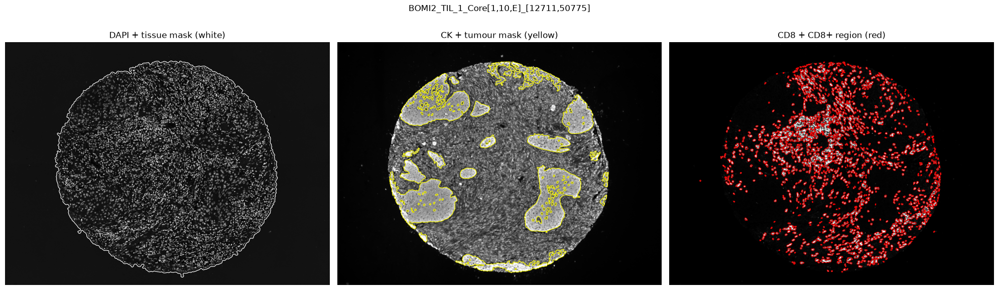

Image 2.63 mm^2 | tissue 1.23 mm^2 | tumour 0.32 mm^2 (26% of tissue) | CK threshold 894 (otsu_in_tissue), CK contrast 1.98


In [4]:
# ---- QC of the masks ----
def show_mask_qc(file_path):
    img, masks = load_image(file_path), get_masks(file_path)
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True, sharey=True)
    panels = [('DAPI + tissue mask (white)', DAPI_CHANNEL, 'tissue', 'w'),
              ('CK + tumour mask (yellow)',  CK_CHANNEL,   'tumour', 'yellow'),
              ('CD8 + CD8+ region (red)',    CD8_CHANNEL,  'cd8',    'red')]
    for ax, (title, ch, key, col) in zip(axes, panels):
        ax.imshow(norm01(img[:, :, ch]), cmap='gray')
        ax.contour(masks[key], levels=[0.5], colors=col, linewidths=0.8)
        ax.set_title(title); ax.axis('off')
    fig.suptitle(sample_name_from_path(file_path), y=0.93)
    plt.tight_layout(); plt.show()
    H, W = masks['tissue'].shape
    tissue_mm2 = masks['tissue'].sum() * PIXEL_AREA_MM2
    tumour_mm2 = masks['tumour'].sum() * PIXEL_AREA_MM2
    print(f"Image {H*W*PIXEL_AREA_MM2:.2f} mm^2 | tissue {tissue_mm2:.2f} mm^2 | "
          f"tumour {tumour_mm2:.2f} mm^2 ({tumour_mm2/tissue_mm2:.0%} of tissue) | "
          f"CK threshold {float(masks['ck_threshold']):.0f} ({TUMOUR_THRESHOLD_MODE}), CK contrast {float(masks['ck_contrast']):.2f}")

show_mask_qc(DEMO_FILE)

### 3.1 Calibrating the tumour mask

`TUMOUR_THRESHOLD_MODE` options (Section 1):
- `otsu_global` 
- `otsu_in_tissue` - Otsu computed on tissue pixels only (default).
- `multiotsu_in_tissue` - three classes inside tissue (background / dim / bright), upper cut used. Stricter.
- `fixed` - a raw CK intensity you choose (`TUMOUR_CK_FIXED`), identical for all cores.

The figure shows, for three cores, the CK histogram inside tissue with each mode's threshold, and the resulting
tumour outline.

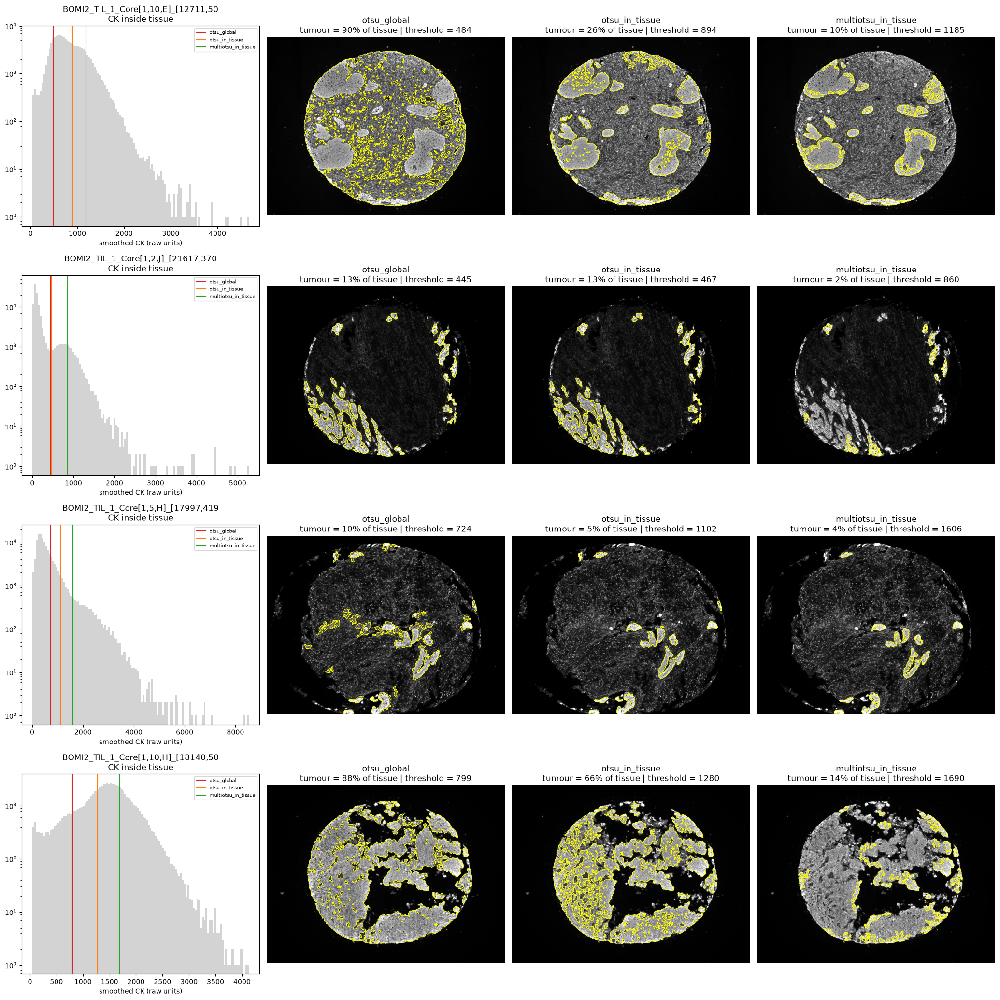

In [5]:
def show_tumour_calibration(files, modes):
    colours = ['tab:red', 'tab:orange', 'tab:green', 'tab:purple']
    fig, axes = plt.subplots(len(files), len(modes) + 1, figsize=(5.2 * (len(modes) + 1), 5.2 * len(files)), squeeze=False)
    for r, f in enumerate(files):
        img = load_image(f)
        ck = img[:, :, CK_CHANNEL]
        shown = norm01(ck)
        res = {m: build_masks(img, tumour_mode=m) for m in modes}
        ck_s = filters.gaussian(ck, sigma=REGION_SIGMA, preserve_range=True)
        vals = ck_s[res[modes[0]]['tissue']][::40]
        ax = axes[r, 0]
        ax.hist(vals, bins=120, log=True, color='lightgrey')
        for m, col in zip(modes, colours):
            ax.axvline(float(res[m]['ck_threshold']), color=col, label=m)
        ax.set_title(f"{sample_name_from_path(f)[:34]}\nCK inside tissue"); ax.set_xlabel('smoothed CK (raw units)')
        ax.legend(fontsize=7)
        for c, m in enumerate(modes, 1):
            ax = axes[r, c]
            ax.imshow(shown, cmap='gray')
            ax.contour(res[m]['tumour'], levels=[0.5], colors='yellow', linewidths=0.8)
            frac = res[m]['tumour'].sum() / max(res[m]['tissue'].sum(), 1)
            ax.set_title(f"{m}\ntumour = {frac:.0%} of tissue | threshold = {float(res[m]['ck_threshold']):.0f}")
            ax.axis('off')
    plt.tight_layout(); plt.show()

if CALIBRATION_CORES:
    cal_files = [f for n in CALIBRATION_CORES for f in file_list if n in f][:4]
else:
    cal_files = [DEMO_FILE] + [file_list[len(file_list) // 3], file_list[2 * len(file_list) // 3]]
cal_modes = list(dict.fromkeys(['otsu_global', 'otsu_in_tissue', 'multiotsu_in_tissue', TUMOUR_THRESHOLD_MODE]))
show_tumour_calibration(cal_files, cal_modes)

### 3.1b Cleaning the tumour mask 

If the minimum object size is only a few hundred pixels (about one cell), isolated bright spots in the stroma and 
thin bright rims at the core edge survive as "tumour",
and every CD8+ cell next to them
is then counted as intratumoural. Two settings control this:

- `TUMOUR_MIN_AREA`: smallest tumour object kept (px; 1 px = 0.25 um^2).
- `TUMOUR_OPEN_RADIUS`: morphological opening, which removes structures thinner than about twice this radius (0 = off).

The figure compares combinations on the demo core, using the threshold mode set in Section 1. 

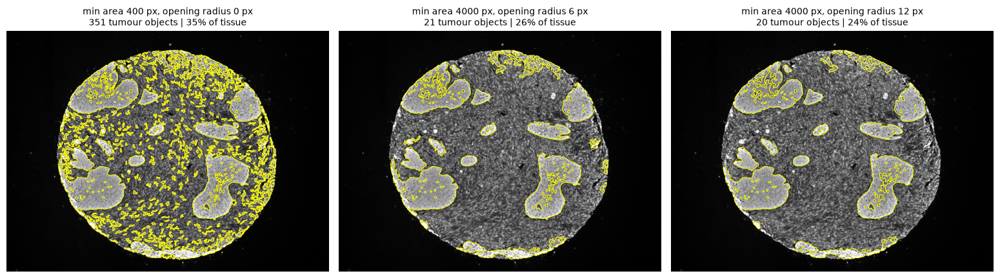

In [6]:
def show_tumour_morphology_calibration(file_path, combos):
    img = load_image(file_path)
    ck = norm01(img[:, :, CK_CHANNEL])
    fig, axes = plt.subplots(1, len(combos), figsize=(5.2 * len(combos), 5.4), squeeze=False)
    for ax, (min_area, open_r) in zip(axes[0], combos):
        m = build_masks(img, tumour_min_area=min_area, tumour_open_radius=open_r)
        n_obj = ndi.label(m['tumour'])[1]
        frac = m['tumour'].sum() / max(m['tissue'].sum(), 1)
        ax.imshow(ck, cmap='gray')
        ax.contour(m['tumour'], levels=[0.5], colors='yellow', linewidths=0.7)
        ax.set_title(f"min area {min_area} px, opening radius {open_r} px\n{n_obj} tumour objects | {frac:.0%} of tissue", fontsize=10)
        ax.axis('off')
    plt.tight_layout(); plt.show()

morph_combos = list(dict.fromkeys([(400, 0), (TUMOUR_MIN_AREA, TUMOUR_OPEN_RADIUS), (4000, 6), (4000, 12)]))
show_tumour_morphology_calibration(DEMO_FILE, morph_combos)

### 3.2 The two "uneven illumination" cores

`KNOWN_ARTIFACT_CORES` are always segmented (so they can serve as a stress test for the three methods, Section 6), but
they only enter the cohort statistics if `INCLUDE_ARTIFACT_CORES = True`. 

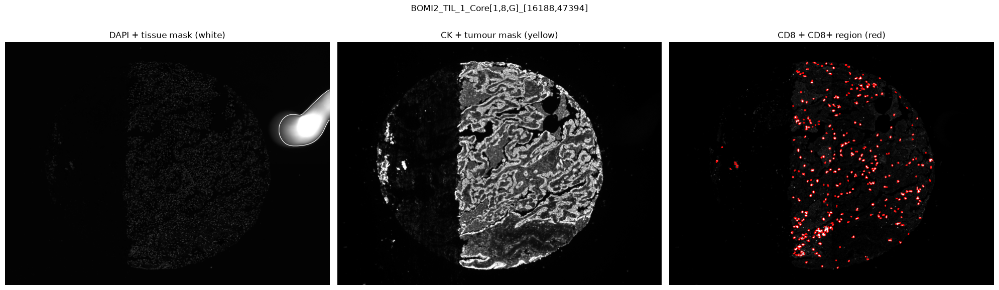

Image 2.63 mm^2 | tissue 0.05 mm^2 | tumour 0.00 mm^2 (0% of tissue) | CK threshold 400 (otsu_in_tissue), CK contrast nan


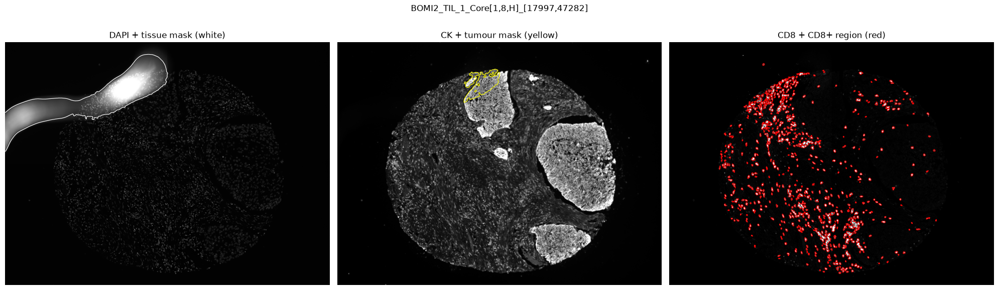

Image 2.63 mm^2 | tissue 0.15 mm^2 | tumour 0.02 mm^2 (13% of tissue) | CK threshold 564 (otsu_in_tissue), CK contrast 7.01


In [7]:
for f in artifact_files:
    show_mask_qc(f)

## 4. Nuclei segmentation

### 4.1 Watershed (classical baseline)

Gaussian smoothing, Otsu threshold, morphological clean-up, distance-transform markers, watershed.

In [8]:
def run_watershed(dapi, sigma=1, hole_area=100, disk_size=1, min_obj=70, min_dist=5, min_final=50):
    smoothed = filters.gaussian(dapi, sigma=sigma)
    binary = smoothed > filters.threshold_otsu(smoothed)
    filled = fill_small_holes(binary, hole_area)
    se = morphology.disk(disk_size)
    opened = morphology.dilation(morphology.erosion(filled, se), se)
    cleaned = drop_small_objects(opened, min_obj)

    distance = ndi.distance_transform_edt(cleaned)
    coords = peak_local_max(distance, min_distance=min_dist, labels=cleaned.astype(int), exclude_border=False)
    peaks = np.zeros(distance.shape, dtype=bool)
    peaks[tuple(coords.T)] = True
    markers, _ = ndi.label(peaks)
    ws = sk_watershed(-distance, markers, mask=cleaned)

    # foreground components that never received a marker: keep them as single objects
    leftover, n_left = ndi.label(cleaned & (ws == 0))
    if n_left:
        ws = np.where(leftover > 0, leftover + ws.max(), ws)

    areas = np.bincount(ws.ravel())
    too_small = np.where(areas < min_final)[0]
    ws[np.isin(ws, too_small[too_small > 0])] = 0
    ws, _, _ = relabel_sequential(ws)           # IMPORTANT: so that labels.max() == number of objects
    return ws.astype(np.int32)

ws_timing_path = os.path.join(WATERSHED_DIR, "timings.json")
ws_timings = read_json(ws_timing_path, {"seconds_per_image": {}})
for i, f in enumerate(file_list, 1):
    out = seg_path('watershed', core_name_from_path(f))
    if os.path.exists(out):
        continue
    t0 = time.time()
    labels = run_watershed(load_image(f)[:, :, DAPI_CHANNEL], **WS_PARAMS)
    ws_timings["seconds_per_image"][os.path.basename(out).replace('.npy', '')] = time.time() - t0
    np.save(out, labels)
    print(f"[{i}/{len(file_list)}] {sample_name_from_path(f)}: {labels.max()} nuclei")
write_json(ws_timing_path, ws_timings)
print("Watershed done.")

Watershed done.


### GPU check (optional, run before 4.2 / 4.3)

StarDist runs on TensorFlow and Cellpose on PyTorch. Each lives in its own conda environment, with its own CUDA
libraries, and the notebook starts them as subprocesses. This cell asks each environment whether it can see the GPU.

In [9]:
def check_gpu(python_path, code_str, name):
    if not os.path.exists(python_path):
        print(f"[{name}] interpreter not found: {python_path}")
        return
    env = os.environ.copy(); env["TF_CPP_MIN_LOG_LEVEL"] = "3"; env["MPLBACKEND"] = "Agg"
    try:
        r = subprocess.run([python_path, "-c", code_str], capture_output=True, text=True, env=env, timeout=240)
    except subprocess.TimeoutExpired:
        print(f"[{name}] timed out"); return
    out = r.stdout.strip().splitlines()
    err = r.stderr.strip().splitlines()
    if out:
        print(f"[{name}] {out[-1]}")
    else:
        print(f"[{name}] failed (exit {r.returncode}): {err[-1] if err else 'no output'}")

try:
    r = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version", "--format=csv,noheader"],
                       capture_output=True, text=True, timeout=30)
    print("[nvidia-smi]", r.stdout.strip() or r.stderr.strip())
except FileNotFoundError:
    print("[nvidia-smi] not found: no NVIDIA driver on this machine?")

check_gpu(CELLPOSE_PYTHON,
          "import torch; ok = torch.cuda.is_available(); "
          "print('torch', torch.__version__, '| CUDA available:', ok, '|', torch.cuda.get_device_name(0) if ok else 'no GPU')",
          "Cellpose / PyTorch")
check_gpu(STARDIST_PYTHON,
          "import tensorflow as tf; print('tensorflow', tf.__version__, '| GPUs:', [d.name for d in tf.config.list_physical_devices('GPU')])",
          "StarDist / TensorFlow")

[nvidia-smi] NVIDIA GeForce GTX 1050 with Max-Q Design, 4096 MiB, 4 MiB, 580.178.04
[Cellpose / PyTorch] torch 2.5.1+cu121 | CUDA available: True | NVIDIA GeForce GTX 1050 with Max-Q Design
[StarDist / TensorFlow] tensorflow 2.21.0 | GPUs: ['/physical_device:GPU:0']


### 4.2 StarDist (`2D_versatile_fluo`, GPU, separate TensorFlow environment)

In [10]:
def run_stardist_batch(files):
    manifest = []
    for f in files:
        out = seg_path('stardist', core_name_from_path(f))
        if not os.path.exists(out):
            manifest.append({"tif_path": f, "dapi_channel": DAPI_CHANNEL, "output_path": out})
    print(f"StarDist: {len(manifest)} images need processing ({len(files) - len(manifest)} already done)")
    if not manifest or not runner_ready(STARDIST_PYTHON, STARDIST_RUNNER_BATCH, 'StarDist'):
        return
    manifest_path = os.path.abspath("stardist_manifest.json")
    write_json(manifest_path, manifest)
    env = os.environ.copy(); env["MPLBACKEND"] = "Agg"; env["PYTHONUNBUFFERED"] = "1"
    t0 = time.time()
    run_streaming([STARDIST_PYTHON, STARDIST_RUNNER_BATCH, manifest_path], env=env)
    elapsed = time.time() - t0
    write_json(os.path.join(STARDIST_DIR, "timings.json"), {"batch_seconds": elapsed, "n_images": len(manifest)})
    print(f"StarDist batch time: {elapsed:.0f}s for {len(manifest)} images")

run_stardist_batch(file_list)

StarDist: 2 images need processing (73 already done)
SKIPPING StarDist: runner script not found: /home/mar-a/stardist_runner_batch.py
   (fix the paths in Section 1; see Section 4.3 for Cellpose setup)


### 4.3 Cellpose

Cellpose needs **PyTorch with CUDA**. 

In [11]:
def run_cellpose_batch(files, max_images=None):
    files = files[:max_images] if max_images else files
    manifest = []
    for f in files:
        out = seg_path('cellpose', core_name_from_path(f))
        if not os.path.exists(out):
            manifest.append({"tif_path": f, "dapi_channel": DAPI_CHANNEL, "output_path": out})
    print(f"Cellpose: {len(manifest)} images need processing ({len(files) - len(manifest)} already done)")
    if not manifest or not runner_ready(CELLPOSE_PYTHON, CELLPOSE_RUNNER, 'Cellpose'):
        return
    manifest_path = os.path.abspath("cellpose_manifest.json")
    write_json(manifest_path, manifest)
    cmd = [CELLPOSE_PYTHON, CELLPOSE_RUNNER, manifest_path, "--batch-size", str(CELLPOSE_BATCH_SIZE)]
    if CELLPOSE_DIAMETER:
        cmd += ["--diameter", str(CELLPOSE_DIAMETER)]
    env = os.environ.copy(); env["PYTHONUNBUFFERED"] = "1"; env["MPLBACKEND"] = "Agg"
    run_streaming(cmd, env=env)

run_cellpose_batch(file_list, max_images=CELLPOSE_MAX_IMAGES)

Cellpose: 0 images need processing (75 already done)


### 4.4 Which methods / cores are available

Cohort-level statistics need a method to cover (nearly) the whole cohort. A method with fewer than
`MIN_CORES_FOR_COHORT` cores (e.g. a Cellpose smoke test) is excluded from cohort-level comparisons but is still
used in the pairwise cell-level comparison on the cores it has.

In [12]:
sample_names = {f: sample_name_from_path(f) for f in file_list}
cores_by_method = {m: {sample_names[f] for f in file_list if seg_exists(m, f)} for m in SEG_METHODS}
for m in SEG_METHODS:
    print(f"{m:10s}: {len(cores_by_method[m])} / {len(file_list)} cores")

cohort_methods = [m for m in SEG_METHODS if len(cores_by_method[m]) >= MIN_CORES_FOR_COHORT]
partial_methods = [m for m in SEG_METHODS if 0 < len(cores_by_method[m]) < MIN_CORES_FOR_COHORT]
assert len(cohort_methods) >= 1, "No method has enough segmented cores - run Section 4 first."
cohort_cores = set.intersection(*[cores_by_method[m] for m in cohort_methods])
art_names = {sample_name_from_path(f) for f in artifact_files}
if not INCLUDE_ARTIFACT_CORES:
    cohort_cores -= art_names
union_cores = set.union(*[cores_by_method[m] for m in cohort_methods])
dropped = sorted(union_cores - cohort_cores - (art_names if not INCLUDE_ARTIFACT_CORES else set()))
print("\nCohort-level methods:", cohort_methods, f"-> {len(cohort_cores)} cores in the cohort statistics")
if not INCLUDE_ARTIFACT_CORES and art_names:
    print(f"   ({len(art_names)} artifact cores are segmented but excluded: INCLUDE_ARTIFACT_CORES = False)")
if dropped:
    print(f"\n*** WARNING: {len(dropped)} core(s) lack a segmentation in at least one cohort method and are DROPPED from the statistics:")
    for sn in dropped:
        print("    ", sn, "- missing in:", [m for m in cohort_methods if sn not in cores_by_method[m]])
    print("    -> run the missing method(s) in Section 4 (check the runner paths in Section 1).")
if partial_methods:
    print("Partial methods (pairwise cell-level comparison only):", partial_methods)

watershed : 75 / 75 cores
stardist  : 73 / 75 cores
cellpose  : 75 / 75 cores

Cohort-level methods: ['watershed', 'stardist', 'cellpose'] -> 73 cores in the cohort statistics
   (2 artifact cores are segmented but excluded: INCLUDE_ARTIFACT_CORES = False)


## 5. Phenotyping and tumour / stroma assignment

In [13]:
def classify_cells(nuclei, cd8_mask):
    # CD8 call per nucleus. Depends only on the CD8 mask and the ring settings 
    if nuclei.shape != cd8_mask.shape:
        raise ValueError(f"label image {nuclei.shape} and CD8 mask {cd8_mask.shape} differ in shape")
    nuclei = nuclei.astype(np.int64)
    n = int(nuclei.max())
    cols = ['label', 'x', 'y', 'area_px', 'ring_area_px', 'cd8_frac', 'cd8_pos']
    if n == 0:
        return pd.DataFrame(columns=cols)

    expanded = expand_labels(nuclei, distance=RING_DISTANCE)
    ring = np.where(nuclei > 0, 0, expanded).ravel().astype(np.int64)
    ring_area = np.bincount(ring, minlength=n + 1)
    cd8_hits = np.bincount(ring, weights=cd8_mask.ravel().astype(np.float64), minlength=n + 1)
    cd8_frac = cd8_hits / np.maximum(ring_area, 1)

    t = measure.regionprops_table(nuclei, properties=('label', 'centroid', 'area'))
    cells = pd.DataFrame({'label': t['label'], 'y': t['centroid-0'], 'x': t['centroid-1'], 'area_px': t['area']})
    lab = cells['label'].to_numpy()
    cells['ring_area_px'] = ring_area[lab]
    cells['cd8_frac'] = cd8_frac[lab]
    cells['cd8_pos'] = (cells['cd8_frac'] > CD8_OVERLAP_THRESHOLD) & (cells['ring_area_px'] > 0)
    return cells[cols]

def assign_compartment(cells, masks):
    cells = cells.copy()
    H, W = masks['tissue'].shape
    if len(cells) == 0:
        cells['compartment'] = pd.Series(dtype=object)
        return cells
    iy = np.clip(np.rint(cells['y'].to_numpy()).astype(int), 0, H - 1)
    ix = np.clip(np.rint(cells['x'].to_numpy()).astype(int), 0, W - 1)
    cells['compartment'] = np.where(masks['tumour'][iy, ix], 'Tumour',
                                    np.where(masks['tissue'][iy, ix], 'Stroma', 'Outside'))
    return cells

def get_cells(file_path, method, masks=None, force=False):
    if masks is None:
        masks = get_masks(file_path)
    path = os.path.join(CACHE_DIR, f"{core_name_from_path(file_path)}__{method}__cd8__{CELL_TAG}.pkl")
    if os.path.exists(path) and not force:
        cells = pd.read_pickle(path)
    else:
        cells = classify_cells(load_seg(method, file_path), masks['cd8'])
        cells.to_pickle(path)
    return assign_compartment(cells, masks)

def summarise_core(cells, masks):
    inside = cells[cells['compartment'] != 'Outside']
    tumour = inside['compartment'] == 'Tumour'
    tissue_mm2 = masks['tissue'].sum() * PIXEL_AREA_MM2
    tumour_mm2 = (masks['tumour'] & masks['tissue']).sum() * PIXEL_AREA_MM2
    return dict(
        n_cells_tumour=int(tumour.sum()), n_cells_stroma=int((~tumour).sum()),
        n_outside=int((cells['compartment'] == 'Outside').sum()),
        n_cd8_tumour=int((tumour & inside['cd8_pos']).sum()),
        n_cd8_stroma=int((~tumour & inside['cd8_pos']).sum()),
        tissue_mm2=tissue_mm2, tumour_mm2=tumour_mm2, stroma_mm2=tissue_mm2 - tumour_mm2,
        ck_threshold=float(masks['ck_threshold']), ck_contrast=float(masks['ck_contrast']))

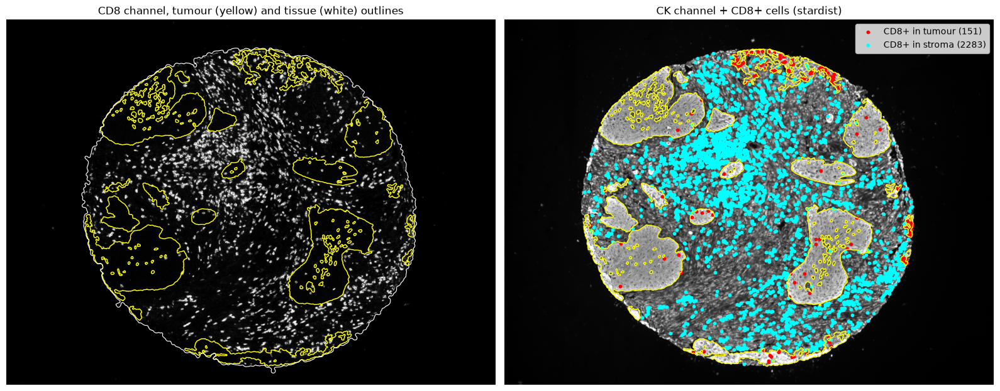

In [14]:
# ---- QC: phenotype calls on the demo core for one method ----
def show_phenotype_qc(file_path, method, crop=(slice(None), slice(None))):
    img, masks = load_image(file_path), get_masks(file_path)
    cells = get_cells(file_path, method, masks)
    y0, x0 = (crop[0].start or 0), (crop[1].start or 0)
    sub = cells[(cells.y >= y0) & (cells.x >= x0)]
    if crop[0].stop: sub = sub[sub.y < crop[0].stop]
    if crop[1].stop: sub = sub[sub.x < crop[1].stop]

    fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
    axes[0].imshow(norm01(img[:, :, CD8_CHANNEL])[crop], cmap='gray')
    axes[0].contour(masks['tumour'][crop], levels=[0.5], colors='yellow', linewidths=1)
    axes[0].contour(masks['tissue'][crop], levels=[0.5], colors='white', linewidths=0.8)
    axes[0].set_title('CD8 channel, tumour (yellow) and tissue (white) outlines')

    axes[1].imshow(norm01(img[:, :, CK_CHANNEL])[crop], cmap='gray')
    groups = [('CD8+ in tumour', sub[sub.cd8_pos & (sub.compartment == 'Tumour')], 'red'),
              ('CD8+ in stroma', sub[sub.cd8_pos & (sub.compartment == 'Stroma')], 'cyan')]
    for label, g, c in groups:
        axes[1].scatter(g.x - x0, g.y - y0, s=10, c=c, label=f"{label} ({len(g)})")
    axes[1].contour(masks['tumour'][crop], levels=[0.5], colors='yellow', linewidths=1)
    axes[1].legend(loc='upper right'); axes[1].set_title(f'CK channel + CD8+ cells ({method})')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

qc_method = cohort_methods[-1] if 'stardist' not in cohort_methods else 'stardist'
if DEMO_FILE and seg_exists(qc_method, DEMO_FILE):
    show_phenotype_qc(DEMO_FILE, qc_method)

### 5.1 Run every method on every core

In [15]:
cells_store = {m: {} for m in SEG_METHODS}          # method -> sample_name -> per-cell DataFrame
summary_rows = {m: [] for m in SEG_METHODS}

for i, f in enumerate(file_list, 1):
    sn = sample_names[f]
    methods_here = [m for m in SEG_METHODS if seg_exists(m, f)]
    if not methods_here:
        continue
    print(f"[{i}/{len(file_list)}] {sn}: {methods_here}")
    try:
        masks = get_masks(f)
    except Exception as e:
        print(f"    masks FAILED: {e}"); continue
    for m in methods_here:
        try:
            cells = get_cells(f, m, masks)
            cells_store[m][sn] = cells
            summary_rows[m].append({'sample_name': sn, **summarise_core(cells, masks)})
        except Exception as e:
            print(f"    {m} FAILED: {e}")

core_summary = {m: pd.DataFrame(r) for m, r in summary_rows.items() if r}
for m, df in core_summary.items():
    print(f"{m}: {len(df)} cores; median tissue area {df.tissue_mm2.median():.2f} mm^2; "
          f"cells outside tissue mask: {df.n_outside.sum() / (df.n_outside.sum() + df.n_cells_tumour.sum() + df.n_cells_stroma.sum()):.2%}")

[1/75] BOMI2_TIL_1_Core[1,1,A]_[5091,35249]: ['watershed', 'stardist', 'cellpose']
[2/75] BOMI2_TIL_1_Core[1,1,C]_[8663,35138]: ['watershed', 'stardist', 'cellpose']
[3/75] BOMI2_TIL_1_Core[1,1,D]_[10473,35233]: ['watershed', 'stardist', 'cellpose']
[4/75] BOMI2_TIL_1_Core[1,1,E]_[12330,35106]: ['watershed', 'stardist', 'cellpose']
[5/75] BOMI2_TIL_1_Core[1,1,G]_[15997,34963]: ['watershed', 'stardist', 'cellpose']
[6/75] BOMI2_TIL_1_Core[1,1,H]_[17759,35233]: ['watershed', 'stardist', 'cellpose']
[7/75] BOMI2_TIL_1_Core[1,1,J]_[21379,35058]: ['watershed', 'stardist', 'cellpose']
[8/75] BOMI2_TIL_1_Core[1,10,A]_[5377,51061]: ['watershed', 'stardist', 'cellpose']
[9/75] BOMI2_TIL_1_Core[1,10,B]_[7234,51013]: ['watershed', 'stardist', 'cellpose']
[10/75] BOMI2_TIL_1_Core[1,10,C]_[9044,50775]: ['watershed', 'stardist', 'cellpose']
[11/75] BOMI2_TIL_1_Core[1,10,E]_[12711,50775]: ['watershed', 'stardist', 'cellpose']
[12/75] BOMI2_TIL_1_Core[1,10,F]_[14521,50918]: ['watershed', 'stardist', '

### 5.2 Tumour-mask sanity check across the cohort

Per-core CK threshold (otsu_in_tissue): median 920, IQR 722-1040, range 410-1348


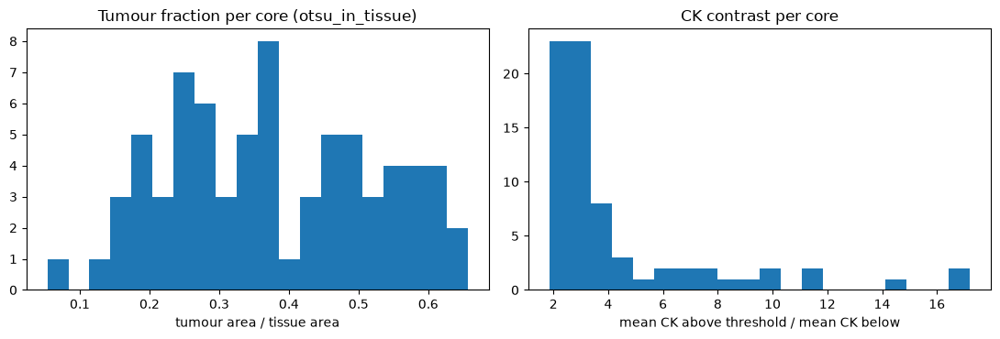

Lowest CK contrast:


,sample_name,tumour_fraction,ck_contrast,ck_threshold
72,"BOMI2_TIL_1_Core[1,9,H]_[18093,48997]",0.60,1.85,1180.03
13,"BOMI2_TIL_1_Core[1,10,H]_[18140,50870]",0.66,1.97,1279.80
10,"BOMI2_TIL_1_Core[1,10,E]_[12711,50775]",0.26,1.98,894.33
53,"BOMI2_TIL_1_Core[1,6,I]_[19950,43901]",0.60,2.02,1020.87
40,"BOMI2_TIL_1_Core[1,4,C]_[8758,40440]",0.42,2.03,1181.77
65,"BOMI2_TIL_1_Core[1,8,I]_[19902,47187]",0.52,2.08,1063.12


Highest tumour fraction:


,sample_name,tumour_fraction,ck_contrast,ck_threshold
13,"BOMI2_TIL_1_Core[1,10,H]_[18140,50870]",0.66,1.97,1279.80
31,"BOMI2_TIL_1_Core[1,3,C]_[8710,38726]",0.65,2.45,1102.17
38,"BOMI2_TIL_1_Core[1,4,A]_[5091,40774]",0.62,2.55,859.56
72,"BOMI2_TIL_1_Core[1,9,H]_[18093,48997]",0.60,1.85,1180.03
53,"BOMI2_TIL_1_Core[1,6,I]_[19950,43901]",0.60,2.02,1020.87
25,"BOMI2_TIL_1_Core[1,2,C]_[8663,37059]",0.60,2.63,980.14


Lowest tumour fraction:


,sample_name,tumour_fraction,ck_contrast,ck_threshold
45,"BOMI2_TIL_1_Core[1,5,H]_[17997,41996]",0.05,3.93,1102.12
28,"BOMI2_TIL_1_Core[1,2,J]_[21617,37011]",0.13,7.59,466.70
34,"BOMI2_TIL_1_Core[1,3,G]_[15950,38583]",0.15,2.58,950.04
35,"BOMI2_TIL_1_Core[1,3,H]_[17807,38662]",0.16,3.45,1081.20
21,"BOMI2_TIL_1_Core[1,12,G]_[16283,54395]",0.16,3.41,595.74
61,"BOMI2_TIL_1_Core[1,8,A]_[5281,47489]",0.18,10.00,861.22


In [16]:
qc = core_summary[cohort_methods[0]][['sample_name', 'tissue_mm2', 'tumour_mm2', 'ck_threshold', 'ck_contrast']].copy()
qc = qc[qc['sample_name'].isin(cohort_cores)]
qc['tumour_fraction'] = qc['tumour_mm2'] / qc['tissue_mm2']
thr = qc['ck_threshold']
print(f"Per-core CK threshold ({TUMOUR_THRESHOLD_MODE}): median {thr.median():.0f}, "
      f"IQR {thr.quantile(.25):.0f}-{thr.quantile(.75):.0f}, range {thr.min():.0f}-{thr.max():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(qc['tumour_fraction'], bins=20)
axes[0].set_xlabel('tumour area / tissue area'); axes[0].set_title(f'Tumour fraction per core ({TUMOUR_THRESHOLD_MODE})')
axes[1].hist(qc['ck_contrast'].dropna(), bins=20)
axes[1].set_xlabel('mean CK above threshold / mean CK below'); axes[1].set_title('CK contrast per core')
plt.tight_layout(); plt.show()
cols = ['sample_name', 'tumour_fraction', 'ck_contrast', 'ck_threshold']
print("Lowest CK contrast:");        display(qc.sort_values('ck_contrast').head(6)[cols].round(2))
print("Highest tumour fraction:");   display(qc.sort_values('tumour_fraction', ascending=False).head(6)[cols].round(2))
print("Lowest tumour fraction:");    display(qc.sort_values('tumour_fraction').head(6)[cols].round(2))

## 6. How different are the segmentations? (descriptive - not accuracy)

In [17]:
def runtime_per_image(method):
    d = {'watershed': WATERSHED_DIR, 'stardist': STARDIST_DIR, 'cellpose': CELLPOSE_DIR}[method]
    t = read_json(os.path.join(d, "timings.json"), {})
    if "seconds_per_image" in t and t["seconds_per_image"]:
        return float(np.mean(list(t["seconds_per_image"].values())))
    if "batch_seconds" in t:
        return t["batch_seconds"] / t["n_images"]
    return MANUAL_RUNTIMES.get(method, np.nan)

rows = []
for m in cohort_methods:
    cs = [cells_store[m][sn] for sn in sorted(cohort_cores)]
    allc = pd.concat(cs, ignore_index=True)
    area_um2 = allc['area_px'] * PIXEL_SIZE_UM ** 2
    inside = allc[allc.compartment != 'Outside']
    rows.append({
        'method': m,
        'nuclei per core (mean)': np.mean([len(c) for c in cs]),
        'median nucleus area (um^2)': area_um2.median(),
        '% nuclei < 28 um^2': 100 * (area_um2 < 28).mean(),
        '% nuclei > 80 um^2': 100 * (area_um2 > 80).mean(),
        '% CD8+': 100 * inside['cd8_pos'].mean(),
        '% in tumour': 100 * (inside.compartment == 'Tumour').mean(),
        'runtime (s/image)': runtime_per_image(m)})
seg_table = pd.DataFrame(rows).set_index('method')
display(seg_table.round(2))
print("Runtime: watershed ran on CPU, StarDist and Cellpose on the GPU (see timings.json files).")

,nuclei per core (mean),median nucleus area (um^2),% nuclei < 28 um^2,% nuclei > 80 um^2,% CD8+,% in tumour,runtime (s/image)
method,,,,,,,
watershed,4654.51,38.00,29.67,11.67,7.15,46.18,4.3
stardist,7545.36,28.75,47.94,7.68,7.17,43.44,22.0
cellpose,7279.55,34.50,35.79,8.08,7.41,43.65,263.6


Runtime: watershed ran on CPU, StarDist and Cellpose on the GPU (see timings.json files).


In [18]:
# ---- Stress test: the artifact cores, segmented by every available method ----
art_here = [f for f in artifact_files if any(sample_names[f] in cells_store[m] for m in SEG_METHODS)]
if art_here:
    typical = {m: int(np.median([len(cells_store[m][sn]) for sn in cohort_cores if sn in cells_store[m]]))
               for m in SEG_METHODS if cells_store[m]}
    rows = []
    for f in art_here:
        sn = sample_names[f]
        row = {'core': sn}
        for m in SEG_METHODS:
            row[f'nuclei {m}'] = len(cells_store[m][sn]) if sn in cells_store[m] else np.nan
        rows.append(row)
    display(pd.DataFrame(rows))
    print("Typical nuclei per core in the cohort (median):", typical)
else:
    print("No artifact core has been segmented yet.")

,core,nuclei watershed,nuclei stardist,nuclei cellpose
0,"BOMI2_TIL_1_Core[1,8,G]_[16188,47394]",5,NaN,5939
1,"BOMI2_TIL_1_Core[1,8,H]_[17997,47282]",92,NaN,6643


Typical nuclei per core in the cohort (median): {'watershed': 4429, 'stardist': 7354, 'cellpose': 6826}


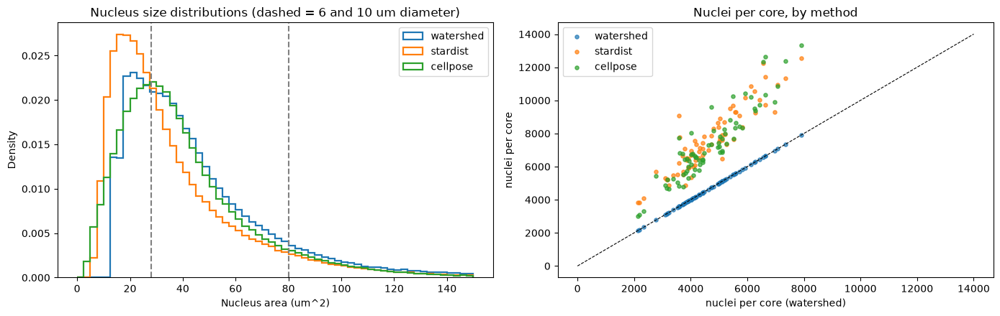

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for m in cohort_methods:
    a = pd.concat([cells_store[m][sn] for sn in sorted(cohort_cores)])['area_px'] * PIXEL_SIZE_UM ** 2
    axes[0].hist(a, bins=np.linspace(0, 150, 61), histtype='step', density=True, label=m, linewidth=1.6)
axes[0].axvline(28, color='grey', ls='--'); axes[0].axvline(80, color='grey', ls='--')
axes[0].set_xlabel('Nucleus area (um^2)'); axes[0].set_ylabel('Density'); axes[0].legend()
axes[0].set_title('Nucleus size distributions (dashed = 6 and 10 um diameter)')

counts = pd.DataFrame({m: {sn: len(cells_store[m][sn]) for sn in cohort_cores} for m in cohort_methods})
for m in cohort_methods:
    axes[1].scatter(counts[cohort_methods[0]], counts[m], s=14, label=m, alpha=.7)
lim = [0, counts.values.max() * 1.05]
axes[1].plot(lim, lim, 'k--', lw=.8)
axes[1].set_xlabel(f'nuclei per core ({cohort_methods[0]})'); axes[1].set_ylabel('nuclei per core')
axes[1].set_title('Nuclei per core, by method'); axes[1].legend()
plt.tight_layout(); plt.show()

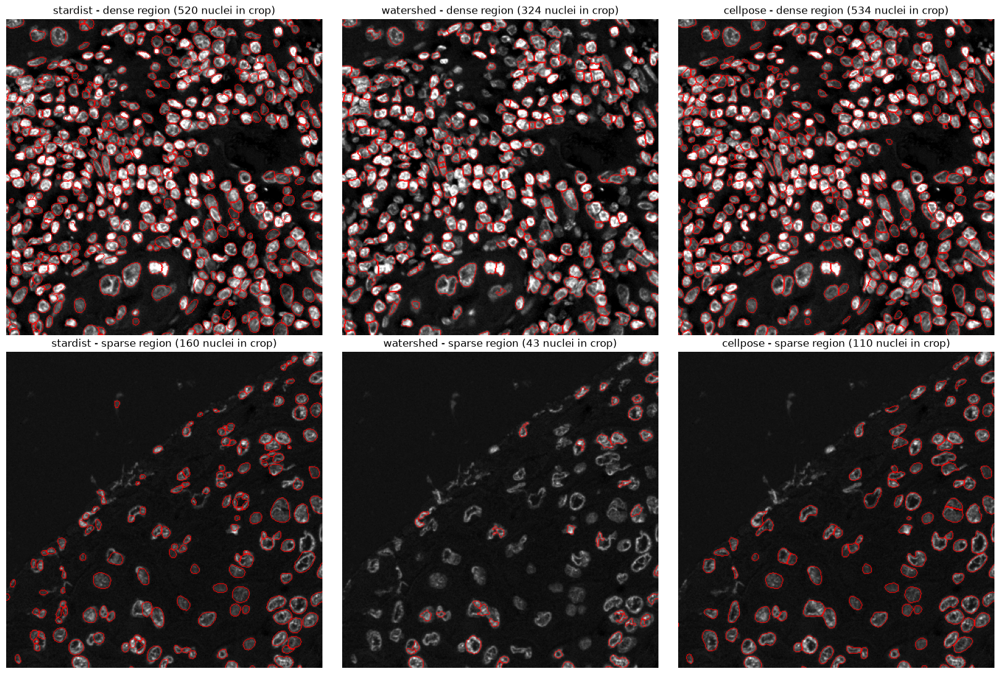

In [20]:
# ---- Side-by-side qualitative comparison on a dense and a sparse region of the demo core ----
def pick_crops(cells, tissue, win=400):
    H, W = tissue.shape
    win = int(min(win, H // 2, W // 2))
    best = {'dense': (None, -1), 'sparse': (None, 10 ** 9)}
    for y0 in range(0, H - win + 1, max(win // 2, 1)):
        for x0 in range(0, W - win + 1, max(win // 2, 1)):
            if tissue[y0:y0 + win, x0:x0 + win].mean() < 0.7:
                continue
            n = ((cells.y >= y0) & (cells.y < y0 + win) & (cells.x >= x0) & (cells.x < x0 + win)).sum()
            if n > best['dense'][1]: best['dense'] = ((y0, x0), n)
            if 0 < n < best['sparse'][1]: best['sparse'] = ((y0, x0), n)
    out = {}
    for k, ((pos), _) in best.items():
        if pos is None:      # no suitable window: centre the crop on the median nucleus position
            pos = (int(np.clip(cells.y.median() - win / 2, 0, H - win)), int(np.clip(cells.x.median() - win / 2, 0, W - win)))
        y0, x0 = pos
        out[k] = (slice(y0, y0 + win), slice(x0, x0 + win))
    return out

def plot_seg_comparison(file_path, methods):
    img = load_image(file_path)
    masks = get_masks(file_path)
    ref = methods[0]
    crops = pick_crops(get_cells(file_path, ref, masks), masks['tissue'])
    labs = {m: load_seg(m, file_path) for m in methods}
    fig, axes = plt.subplots(len(crops), len(methods), figsize=(5.5 * len(methods), 5.5 * len(crops)), squeeze=False)
    for r, (cname, crop) in enumerate(crops.items()):
        dapi = norm01(img[:, :, DAPI_CHANNEL])[crop]
        for c, m in enumerate(methods):
            lab = labs[m][crop]
            b = find_boundaries(lab, mode='inner')
            ax = axes[r, c]
            ax.imshow(dapi, cmap='gray')
            ax.imshow(np.ma.masked_where(~b, b), cmap='autumn', alpha=.9)
            ax.set_title(f"{m} - {cname} region ({len(np.unique(lab)) - 1} nuclei in crop)")
            ax.axis('off')
    plt.tight_layout(); plt.show()

methods_for_demo = [m for m in ['stardist', 'watershed', 'cellpose'] if seg_exists(m, DEMO_FILE)]
if len(methods_for_demo) >= 2:
    plot_seg_comparison(DEMO_FILE, methods_for_demo)
else:
    print("Need at least two methods segmented on the demo core for the visual comparison.")

#### 6.1 Stress test: the artifact cores

BOMI2_TIL_1_Core[1,8,G]_[16188,47394]


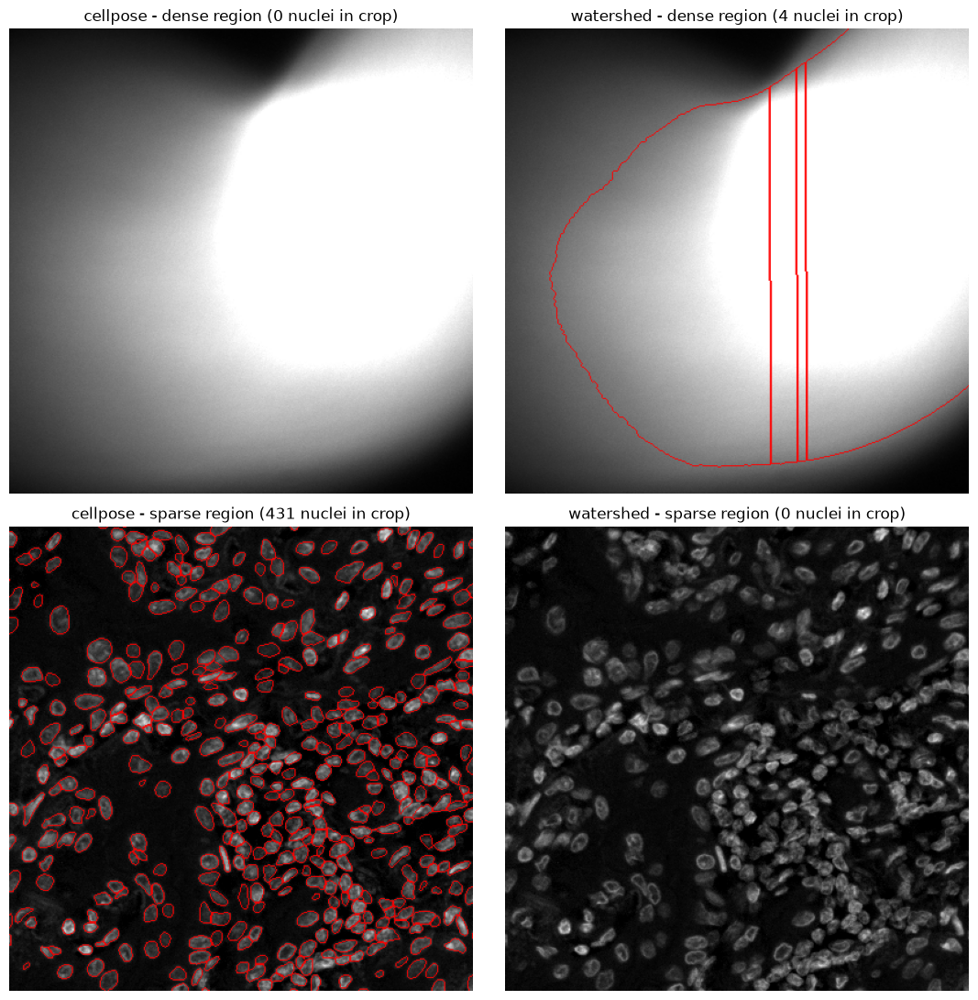

BOMI2_TIL_1_Core[1,8,H]_[17997,47282]


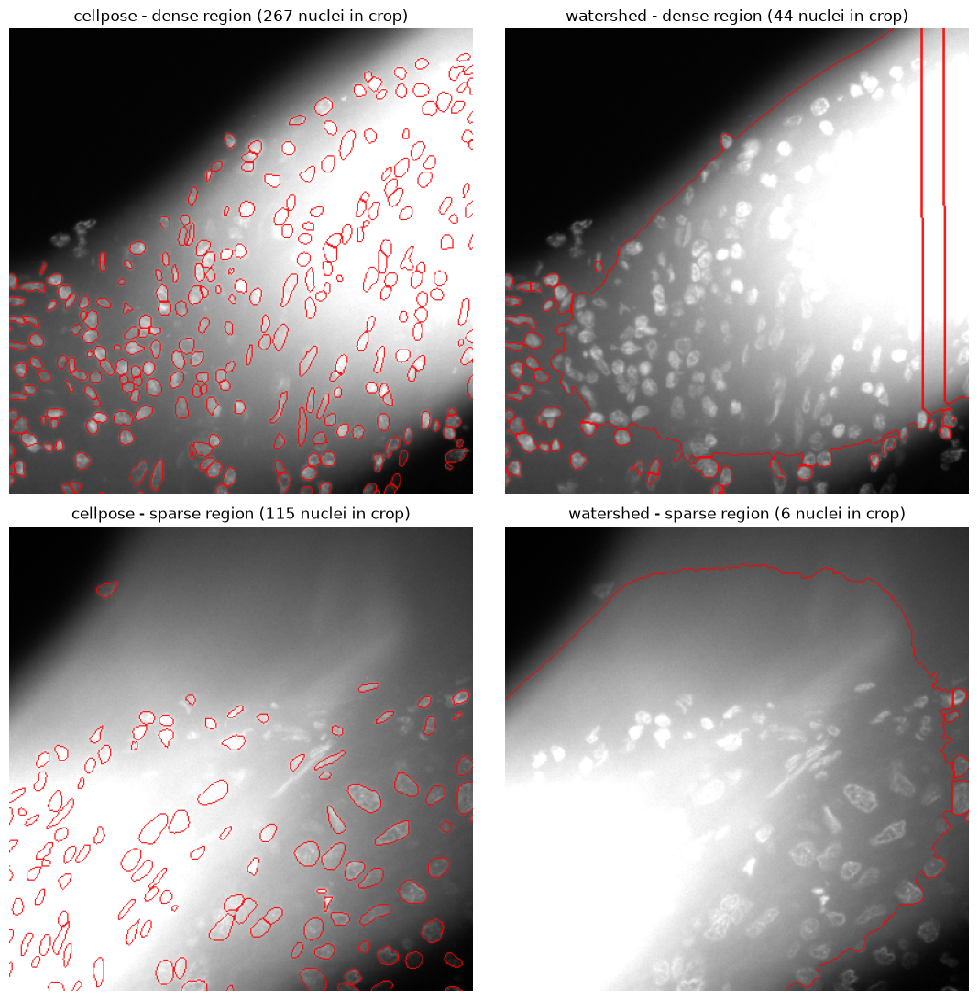

In [21]:
for f in art_here:
    ms = [m for m in ['stardist', 'cellpose', 'watershed'] if sample_names[f] in cells_store[m]]
    if len(ms) >= 2:
        print(sample_names[f])
        plot_seg_comparison(f, ms)

## 7. Clinical data and per-method density tables

Densities are cells / mm^2 of the relevant compartment. A compartment smaller than `MIN_COMPARTMENT_MM2`
gets `NaN` rather than an unstable density.

In [22]:
clinical_df = pd.read_csv(CLINICAL_CSV)
clinical_df['sample_name'] = clinical_df['sample_name'].astype(str)
print("clinical rows:", len(clinical_df), "| unique sample_name:", clinical_df['sample_name'].nunique())
print("columns:", list(clinical_df.columns))
cands = [c for c in clinical_df.columns if any(k in c.lower() for k in ('patient', 'id', 'case', 'subject'))]
for c in cands:
    print(f"  candidate ID column {c!r}: {clinical_df[c].nunique()} unique values")
if PATIENT_ID_COL is None and clinical_df['sample_name'].nunique() != len(clinical_df):
    print("WARNING: duplicated sample_name rows in the clinical table.")

needed = ['Dead/Alive', 'time (days)', 'Age', 'Sex', 'Smoking', 'Stage', 'Performance status']
missing = [c for c in needed if c not in clinical_df.columns]
assert not missing, f"clinical table lacks expected columns: {missing}"
KEY = PATIENT_ID_COL or 'sample_name'

clinical rows: 75 | unique sample_name: 75
columns: ['ID', 'sample_name', 'time (days)', 'Dead/Alive', 'Age', 'Sex', 'Smoking', 'Stage', 'Performance status']
  candidate ID column 'ID': 46 unique values


In [23]:
COUNT_COLS = ['n_cores', 'n_cells_tumour', 'n_cells_stroma', 'n_outside', 'n_cd8_tumour', 'n_cd8_stroma',
              'tissue_mm2', 'tumour_mm2', 'stroma_mm2']

def add_densities(d):
    d = d.copy()
    d['n_cd8_total'] = d['n_cd8_tumour'] + d['n_cd8_stroma']
    for comp, area_col, n_col in [('total', 'tissue_mm2', 'n_cd8_total'),
                                  ('tumour', 'tumour_mm2', 'n_cd8_tumour'),
                                  ('stroma', 'stroma_mm2', 'n_cd8_stroma')]:
        d[f'cd8_density_{comp}'] = d[n_col] / d[area_col].where(d[area_col] >= MIN_COMPARTMENT_MM2)
    d['tumour_fraction'] = d['tumour_mm2'] / d['tissue_mm2']
    return d

def make_patient_table(core_summary_df, clinical):
    d = clinical.merge(core_summary_df, on='sample_name', how='inner')
    d['n_cores'] = 1
    if PATIENT_ID_COL is not None:
        agg = {c: 'sum' for c in COUNT_COLS}
        agg.update({c: 'first' for c in d.columns if c not in COUNT_COLS and c != PATIENT_ID_COL})
        d = d.groupby(PATIENT_ID_COL, as_index=False).agg(agg)
    return add_densities(d)

tables = {}
for m in cohort_methods:
    cs = core_summary[m]
    cs = cs[cs.sample_name.isin(cohort_cores)]
    tables[m] = make_patient_table(cs, clinical_df)
    print(f"{m}: {len(tables[m])} rows after merge ({len(cs)} cores in cohort, {len(clinical_df)} clinical rows)")

for m, t in tables.items():
    nan_counts = {e: int(t[e].isna().sum()) for e in EXPOSURES}
    print(f"{m}: rows with NaN density (compartment < {MIN_COMPARTMENT_MM2} mm^2): {nan_counts}")
    if all(v == len(t) for v in nan_counts.values()):
        print("   -> ALL densities are NaN: check PIXEL_SIZE_UM and MIN_COMPARTMENT_MM2.")

unmatched_cores = sorted(cohort_cores - set(clinical_df['sample_name']))
if unmatched_cores:
    print(f"\n{len(unmatched_cores)} imaged cores have no clinical row, e.g. {unmatched_cores[:3]}")
tables[cohort_methods[0]][['n_cores', 'tissue_mm2', 'tumour_mm2', 'tumour_fraction'] + EXPOSURES].describe().round(2)

watershed: 46 rows after merge (73 cores in cohort, 75 clinical rows)
stardist: 46 rows after merge (73 cores in cohort, 75 clinical rows)
cellpose: 46 rows after merge (73 cores in cohort, 75 clinical rows)
watershed: rows with NaN density (compartment < 0.05 mm^2): {'cd8_density_total': 0, 'cd8_density_tumour': 0, 'cd8_density_stroma': 0}
stardist: rows with NaN density (compartment < 0.05 mm^2): {'cd8_density_total': 0, 'cd8_density_tumour': 0, 'cd8_density_stroma': 0}
cellpose: rows with NaN density (compartment < 0.05 mm^2): {'cd8_density_total': 0, 'cd8_density_tumour': 0, 'cd8_density_stroma': 0}


,n_cores,tissue_mm2,tumour_mm2,tumour_fraction,cd8_density_total,cd8_density_tumour,cd8_density_stroma
count,46.00,46.00,46.00,46.00,46.00,46.00,46.00
mean,1.59,2.08,0.75,0.37,300.64,159.24,393.56
std,0.50,1.21,0.46,0.13,391.21,484.23,430.95
min,1.00,0.69,0.10,0.15,14.23,2.68,12.14
25%,1.00,1.07,0.38,0.26,78.27,18.97,107.15
50%,2.00,2.01,0.70,0.35,157.76,46.19,234.32
75%,2.00,2.56,0.99,0.50,369.08,105.92,478.26
max,2.00,5.27,1.97,0.63,2287.58,3281.04,2100.68


## 8. Does the method change the density measurements?

For each pair of methods, on the same patients: Spearman correlation of the density, and how many patients
**change High/Low group**.

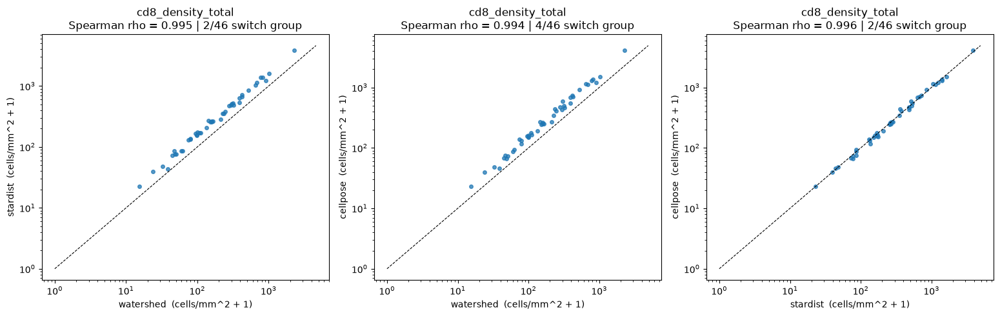

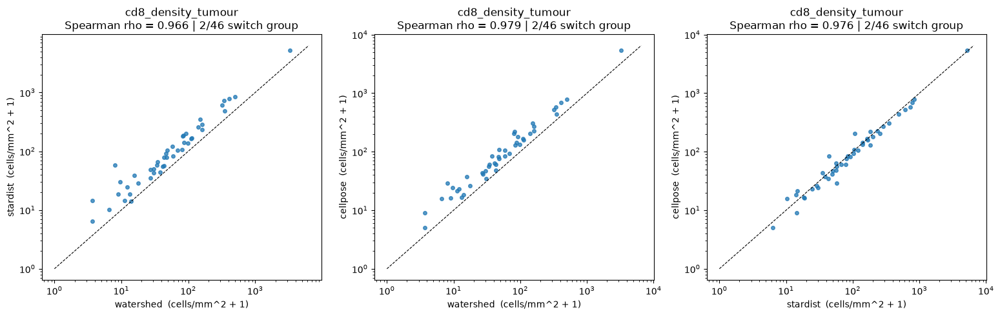

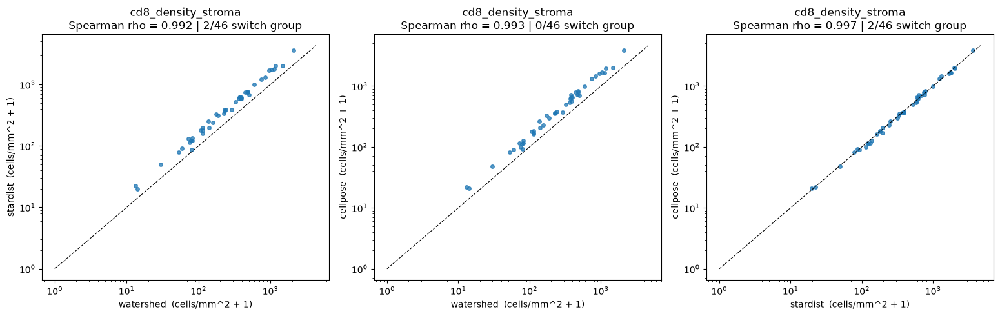

,exposure,pair,n,spearman_rho,median_ratio (a/b),patients switching High/Low,% switching
0,cd8_density_total,watershed vs stardist,46,0.995,0.617,2,4.348
1,cd8_density_total,watershed vs cellpose,46,0.994,0.633,4,8.696
2,cd8_density_total,stardist vs cellpose,46,0.996,1.018,2,4.348
3,cd8_density_tumour,watershed vs stardist,46,0.966,0.589,2,4.348
4,cd8_density_tumour,watershed vs cellpose,46,0.979,0.607,2,4.348
5,cd8_density_tumour,stardist vs cellpose,46,0.976,1.092,2,4.348
6,cd8_density_stroma,watershed vs stardist,46,0.992,0.624,2,4.348
7,cd8_density_stroma,watershed vs cellpose,46,0.993,0.630,0,0.000
8,cd8_density_stroma,stardist vs cellpose,46,0.997,1.013,2,4.348


In [24]:
from scipy.stats import spearmanr

def agreement(tables, exposure):
    methods = list(tables)
    pairs = list(itertools.combinations(methods, 2))
    fig, axes = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 5), squeeze=False)
    rows = []
    for ax, (a, b) in zip(axes[0], pairs):
        da = tables[a].set_index(KEY)[exposure]; db = tables[b].set_index(KEY)[exposure]
        both = pd.concat([da, db], axis=1, keys=[a, b]).dropna()
        if len(both) < 3:
            ax.set_title(f'{exposure}: <3 patients with valid density in both methods'); continue
        rho = spearmanr(both[a], both[b])[0]
        hi_a = both[a] >= both[a].median(); hi_b = both[b] >= both[b].median()
        flips = int((hi_a != hi_b).sum())
        ax.scatter(both[a] + 1, both[b] + 1, s=16, alpha=.75)
        lim = [1, both.values.max() * 1.2 + 1]
        ax.plot(lim, lim, 'k--', lw=.8); ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xlabel(f'{a}  (cells/mm^2 + 1)'); ax.set_ylabel(f'{b}  (cells/mm^2 + 1)')
        ax.set_title(f'{exposure}\nSpearman rho = {rho:.3f} | {flips}/{len(both)} switch group')
        rows.append({'exposure': exposure, 'pair': f'{a} vs {b}', 'n': len(both), 'spearman_rho': rho,
                     'median_ratio (a/b)': float((both[a] / both[b].replace(0, np.nan)).median()),
                     'patients switching High/Low': flips, '% switching': 100 * flips / len(both)})
    plt.tight_layout(); plt.show()
    return pd.DataFrame(rows)

if len(tables) >= 2:
    agree_df = pd.concat([agreement(tables, e) for e in EXPOSURES], ignore_index=True)
    display(agree_df.round(3))
else:
    print("Need at least two cohort-level methods.")

### 8.1 Cell-level agreement between methods

Nuclei from two methods are matched one-to-one when their IoU is above 0.5. 

**IoU (intersection over union)** = (pixels shared by two nuclei) / (pixels covered by either). 1 = identical outline, 0 = no overlap.

In [25]:
def match_nuclei(lab_a, lab_b, iou_thr=0.5):
    a = lab_a.ravel().astype(np.int64); b = lab_b.ravel().astype(np.int64)
    na, nb = int(a.max()) + 1, int(b.max()) + 1
    both = (a > 0) & (b > 0)
    pair = a[both] * nb + b[both]
    uniq, inter = np.unique(pair, return_counts=True)
    ia, ib = uniq // nb, uniq % nb
    area_a = np.bincount(a, minlength=na); area_b = np.bincount(b, minlength=nb)
    iou = inter / (area_a[ia] + area_b[ib] - inter)
    keep = iou > iou_thr                    # IoU > 0.5 guarantees a one-to-one match
    return ia[keep], ib[keep]

def cell_concordance(a, b, max_cores=None):
    shared = [f for f in file_list if sample_names[f] in cells_store[a] and sample_names[f] in cells_store[b]
              and (INCLUDE_ARTIFACT_CORES or sample_names[f] not in art_names)]
    shared = shared[:max_cores] if max_cores else shared
    tot = dict(n_a=0, n_b=0, matched=0, same_cd8=0, same_comp=0, cd8_a=0, cd8_a_matched_cd8_b=0)
    for f in shared:
        sn = sample_names[f]
        ca = cells_store[a][sn].set_index('label'); cb = cells_store[b][sn].set_index('label')
        ia, ib = match_nuclei(load_seg(a, f), load_seg(b, f))
        pa, pb = ca.loc[ia, 'cd8_pos'].to_numpy(), cb.loc[ib, 'cd8_pos'].to_numpy()
        tot['n_a'] += len(ca); tot['n_b'] += len(cb); tot['matched'] += len(ia)
        tot['same_cd8'] += int((pa == pb).sum())
        tot['same_comp'] += int((ca.loc[ia, 'compartment'].to_numpy() == cb.loc[ib, 'compartment'].to_numpy()).sum())
        tot['cd8_a'] += int(ca['cd8_pos'].sum()); tot['cd8_a_matched_cd8_b'] += int((pa & pb).sum())
    return {'pair': f'{a} vs {b}', 'cores': len(shared),
            f'% of {a} nuclei matched': 100 * tot['matched'] / max(tot['n_a'], 1),
            f'% of {b} nuclei matched': 100 * tot['matched'] / max(tot['n_b'], 1),
            '% matched pairs, same CD8 call': 100 * tot['same_cd8'] / max(tot['matched'], 1),
            '% matched pairs, same compartment': 100 * tot['same_comp'] / max(tot['matched'], 1),
            f'CD8+ in {a}': tot['cd8_a'],
            f'% of CD8+ {a} with a CD8+ {b} match': 100 * tot['cd8_a_matched_cd8_b'] / max(tot['cd8_a'], 1)}

available = [m for m in SEG_METHODS if cells_store[m]]
for a, b in itertools.combinations(available, 2):
    res = cell_concordance(a, b, N_CONCORDANCE_CORES)
    print(pd.Series({k: (round(v, 2) if isinstance(v, float) else v) for k, v in res.items()}).to_string(), "\n")

pair                                              watershed vs stardist
cores                                                                73
% of watershed nuclei matched                                     74.45
% of stardist nuclei matched                                      45.93
% matched pairs, same CD8 call                                    98.78
% matched pairs, same compartment                                 99.43
CD8+ in watershed                                                 24273
% of CD8+ watershed with a CD8+ stardist match                    79.87 

pair                                              watershed vs cellpose
cores                                                                73
% of watershed nuclei matched                                     75.97
% of cellpose nuclei matched                                      48.58
% matched pairs, same CD8 call                                    98.75
% matched pairs, same compartment                             

### 8.2 What do the methods disagree about?


BOMI2_TIL_1_Core[1,10,E]_[12711,50775]: stardist 10872 nuclei (2514 without a match in cellpose) | cellpose 10223 nuclei (1865 without a match in stardist)


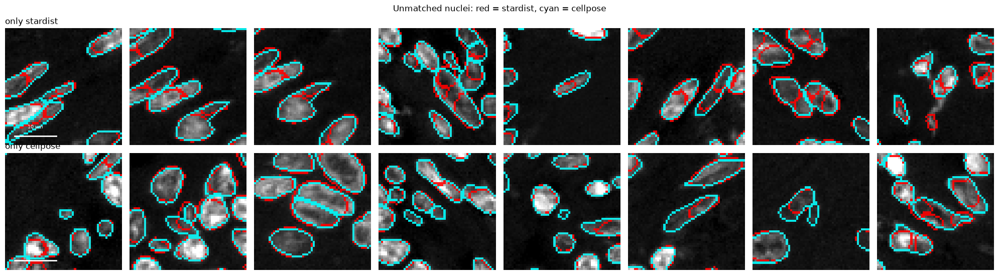

BOMI2_TIL_1_Core[1,10,E]_[12711,50775]: watershed 6135 nuclei (1454 without a match in stardist) | stardist 10872 nuclei (6191 without a match in watershed)


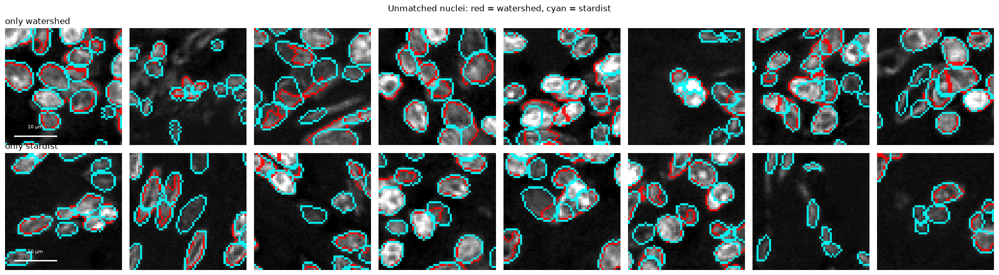

In [26]:
from matplotlib.colors import ListedColormap

def disagreement_gallery(file_path, a, b, n=8, half=28, seed=0):
    sn = sample_name_from_path(file_path)
    la, lb = load_seg(a, file_path), load_seg(b, file_path)
    ia, ib = match_nuclei(la, lb)
    ca, cb = cells_store[a][sn], cells_store[b][sn]
    only_a, only_b = ca[~ca['label'].isin(ia)], cb[~cb['label'].isin(ib)]
    print(f"{sn}: {a} {len(ca)} nuclei ({len(only_a)} without a match in {b}) | "
          f"{b} {len(cb)} nuclei ({len(only_b)} without a match in {a})")
    img = norm01(load_image(file_path)[:, :, DAPI_CHANNEL], 99.8)
    H, W = img.shape
    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 5.6), squeeze=False)
    for r, (tbl, name) in enumerate([(only_a, a), (only_b, b)]):
        tbl = tbl[(tbl.y >= half) & (tbl.y < H - half) & (tbl.x >= half) & (tbl.x < W - half)]
        pick = tbl.sample(min(n, len(tbl)), random_state=seed) if len(tbl) else tbl
        for c in range(n):
            ax = axes[r, c]; ax.axis('off')
            if c >= len(pick):
                continue
            y, x = int(pick.iloc[c].y), int(pick.iloc[c].x)
            sl = (slice(y - half, y + half), slice(x - half, x + half))
            ax.imshow(img[sl], cmap='gray', vmin=0, vmax=1)
            for lab, col in [(la, 'red'), (lb, 'cyan')]:
                bnd = find_boundaries(lab[sl], mode='inner')
                ax.imshow(np.ma.masked_where(~bnd, bnd), cmap=ListedColormap([col]), alpha=.9, interpolation='nearest')
            if c == 0:
                ax.set_title(f"only {name}", fontsize=12, loc='left')
                bar_px = 10 / 0.5
                ax.plot([4, 4 + bar_px], [2 * half - 5] * 2, color="white", lw=2)
                ax.text(4 + bar_px / 2, 2 * half - 8, "10 µm", color="white",
                        ha="center", va="bottom", fontsize=7)
    fig.suptitle(f"Unmatched nuclei: red = {a}, cyan = {b}", y=0.98)
    plt.tight_layout(); plt.show()

for a, b in [('stardist', 'cellpose'), ('watershed', 'stardist')]:
    if DEMO_FILE and sample_names[DEMO_FILE] in cells_store[a] and sample_names[DEMO_FILE] in cells_store[b]:
        disagreement_gallery(DEMO_FILE, a, b)

## 9. Survival analysis, repeated per segmentation method

In [27]:
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test

STAGE_MAP = {'Ia': 'Early', 'Ib': 'Early', 'IIa': 'Locally advanced', 'IIb': 'Locally advanced',
             'IIIa': 'Advanced', 'IV': 'Advanced'}

def add_survival_columns(d):
    d = d[d['Dead/Alive'].notna()].copy()                    # do not silently censor missing status
    d['event'] = (d['Dead/Alive'].astype(str).str.strip().str.lower() == 'dead').astype(int)
    d['time'] = pd.to_numeric(d['time (days)'], errors='coerce')
    return d

def exposure_columns(d, exposure):
    d = d.dropna(subset=['time', exposure]).copy()
    d['high'] = (d[exposure] >= d[exposure].median()).astype(int)
    lx = np.log1p(d[exposure])
    d['log_z'] = (lx - lx.mean()) / lx.std()
    d['log2'] = np.log2(1 + d[exposure])        # for 'HR per doubling of density'
    return d

def cox_univariable(d, col):
    cph = CoxPHFitter().fit(d[['time', 'event', col]], 'time', 'event')
    s = cph.summary.loc[col]
    return dict(HR=s['exp(coef)'], lo=s['exp(coef) lower 95%'], hi=s['exp(coef) upper 95%'],
                p=s['p'], cindex=cph.concordance_index_)

def multivariable_frame(d, exposure_col, covariates=None):
    covs = list(covariates or MULTI_COVARIATES)
    x = d[['time', 'event', exposure_col] + covs].copy()
    unmapped = []
    if 'Stage' in covs:
        x['Stage'] = x['Stage'].astype(str).str.strip()
        x['stage_group'] = x['Stage'].map(STAGE_MAP)
        unmapped = sorted(x.loc[x['stage_group'].isna(), 'Stage'].unique())
        x = x.drop(columns='Stage')
    for c in ['Age', 'Performance status', 'tumour_fraction']:
        if c in x.columns:
            x[c] = pd.to_numeric(x[c], errors='coerce')
    n_before = len(x)
    x = x.dropna()
    cat = [c for c in ['Sex', 'Smoking', 'stage_group'] if c in x.columns]
    x = pd.get_dummies(x, columns=cat, drop_first=True, dtype=float)
    x = x.loc[:, x.nunique() > 1]
    return x, n_before - len(x), unmapped

def fit_multivariable(d, exposure_col, covariates=None):
    x, n_drop, unmapped = multivariable_frame(d, exposure_col, covariates)
    cph = CoxPHFitter().fit(x, 'time', 'event')
    s = cph.summary.loc[exposure_col]
    info = dict(HR=s['exp(coef)'], lo=s['exp(coef) lower 95%'], hi=s['exp(coef) upper 95%'], p=s['p'],
                n=len(x), events=int(x['event'].sum()), n_params=x.shape[1] - 2,
                n_dropped=n_drop, unmapped_stages=unmapped)
    return cph, x, info

def survival_summary(tables, exposures):
    rows, models = [], {}
    for exposure in exposures:
        for m, t in tables.items():
            d = exposure_columns(add_survival_columns(t), exposure)
            hi, lo = d[d.high == 1], d[d.high == 0]
            lr = logrank_test(hi['time'], lo['time'], hi['event'], lo['event'])
            ub, uc, ud = cox_univariable(d, 'high'), cox_univariable(d, 'log_z'), cox_univariable(d, 'log2')
            row = dict(exposure=exposure, method=m, n=len(d), events=int(d['event'].sum()),
                       cutpoint=d[exposure].median(), logrank_p=lr.p_value,
                       HR_high_uni=ub['HR'], HR_high_uni_lo=ub['lo'], HR_high_uni_hi=ub['hi'], p_high_uni=ub['p'],
                       HR_cont_uni=uc['HR'], HR_cont_uni_lo=uc['lo'], HR_cont_uni_hi=uc['hi'],
                       p_cont_uni=uc['p'], cindex_cont=uc['cindex'],
                       HR_dbl_uni=ud['HR'], HR_dbl_uni_lo=ud['lo'], HR_dbl_uni_hi=ud['hi'], p_dbl_uni=ud['p'])
            try:
                cb, xb, ib = fit_multivariable(d, 'high')
                cc, xc, ic = fit_multivariable(d, 'log_z')
                row.update(HR_high_multi=ib['HR'], HR_high_multi_lo=ib['lo'], HR_high_multi_hi=ib['hi'],
                           p_high_multi=ib['p'], HR_cont_multi=ic['HR'], HR_cont_multi_lo=ic['lo'],
                           HR_cont_multi_hi=ic['hi'], p_cont_multi=ic['p'],
                           n_multi=ib['n'], events_multi=ib['events'], params_multi=ib['n_params'],
                           dropped_multi=ib['n_dropped'])
                models[(exposure, m)] = (cc, xc)          # the primary (continuous) adjusted model
                if ib['unmapped_stages']:
                    print(f"  unmapped Stage values for {m}/{exposure}: {ib['unmapped_stages']}")
            except Exception as e:
                print(f"  multivariable model failed for {m}/{exposure}: {e}")
            rows.append(row)
    return pd.DataFrame(rows), models

results_df, cox_models = survival_summary(tables, EXPOSURES)

def fmt(hr, lo, hi, p):
    return f"{hr:.2f} ({lo:.2f}-{hi:.2f}), p={p:.3f}"

pretty = pd.DataFrame({
    'exposure': results_df.exposure, 'method': results_df.method,
    'n / events': results_df.n.astype(str) + ' / ' + results_df.events.astype(str),
    '[PRIMARY] HR per SD log-density (uni)': [fmt(*r) for r in results_df[['HR_cont_uni', 'HR_cont_uni_lo', 'HR_cont_uni_hi', 'p_cont_uni']].values],
    'HR per doubling of density (uni)': [fmt(*r) for r in results_df[['HR_dbl_uni', 'HR_dbl_uni_lo', 'HR_dbl_uni_hi', 'p_dbl_uni']].values],
    'C-index (continuous)': results_df.cindex_cont.round(3)})
if 'HR_cont_multi' in results_df:
    pretty['[PRIMARY] HR per SD (adjusted)'] = [fmt(*r) for r in results_df[['HR_cont_multi', 'HR_cont_multi_lo', 'HR_cont_multi_hi', 'p_cont_multi']].values]
pretty['[secondary] HR High vs Low (uni)'] = [fmt(*r) for r in results_df[['HR_high_uni', 'HR_high_uni_lo', 'HR_high_uni_hi', 'p_high_uni']].values]
pretty['[secondary] log-rank p'] = results_df.logrank_p.round(4)
if 'HR_high_multi' in results_df:
    pretty['[secondary] HR High vs Low (adjusted)'] = [fmt(*r) for r in results_df[['HR_high_multi', 'HR_high_multi_lo', 'HR_high_multi_hi', 'p_high_multi']].values]
pd.set_option('display.max_colwidth', 60, 'display.width', 250)
display(pretty)
if 'events_multi' in results_df:
    r = results_df.iloc[0]
    print(f"Multivariable model: {int(r.events_multi)} events for {int(r.params_multi)} parameters "
          f"= {r.events_multi / r.params_multi:.1f} events per parameter (guideline: ~10). Read the adjusted HRs cautiously.")

,exposure,method,n / events,[PRIMARY] HR per SD log-density (uni),HR per doubling of density (uni),C-index (continuous),[PRIMARY] HR per SD (adjusted),[secondary] HR High vs Low (uni),[secondary] log-rank p,[secondary] HR High vs Low (adjusted)
0,cd8_density_total,watershed,46 / 32,"0.84 (0.59-1.21), p=0.349","0.90 (0.72-1.13), p=0.349",0.554,"1.05 (0.72-1.55), p=0.789","0.69 (0.34-1.40), p=0.304",0.3014,"0.80 (0.37-1.76), p=0.579"
1,cd8_density_total,stardist,46 / 32,"0.85 (0.60-1.21), p=0.365","0.90 (0.73-1.12), p=0.365",0.552,"1.07 (0.73-1.57), p=0.714","0.55 (0.27-1.14), p=0.107",0.1023,"0.65 (0.30-1.43), p=0.287"
2,cd8_density_total,cellpose,46 / 32,"0.85 (0.60-1.20), p=0.354","0.90 (0.73-1.12), p=0.354",0.556,"1.07 (0.73-1.57), p=0.733","0.55 (0.27-1.13), p=0.104",0.0989,"0.64 (0.29-1.38), p=0.254"
3,cd8_density_tumour,watershed,46 / 32,"0.80 (0.55-1.16), p=0.237","0.89 (0.74-1.08), p=0.237",0.594,"0.91 (0.60-1.38), p=0.655","0.60 (0.29-1.24), p=0.170",0.1653,"0.89 (0.40-1.99), p=0.775"
4,cd8_density_tumour,stardist,46 / 32,"0.76 (0.52-1.10), p=0.149","0.87 (0.71-1.05), p=0.149",0.598,"0.86 (0.56-1.33), p=0.498","0.58 (0.28-1.19), p=0.136",0.1313,"0.82 (0.37-1.85), p=0.638"
5,cd8_density_tumour,cellpose,46 / 32,"0.79 (0.55-1.13), p=0.197","0.88 (0.73-1.07), p=0.197",0.596,"0.92 (0.60-1.40), p=0.690","0.70 (0.34-1.44), p=0.332",0.3297,"0.90 (0.39-2.09), p=0.813"
6,cd8_density_stroma,watershed,46 / 32,"0.88 (0.62-1.27), p=0.498","0.93 (0.75-1.15), p=0.498",0.543,"1.09 (0.75-1.59), p=0.648","0.70 (0.34-1.43), p=0.325",0.3228,"0.78 (0.36-1.71), p=0.541"
7,cd8_density_stroma,stardist,46 / 32,"0.89 (0.62-1.27), p=0.514","0.93 (0.76-1.15), p=0.514",0.531,"1.12 (0.77-1.62), p=0.559","0.88 (0.43-1.79), p=0.725",0.7243,"0.95 (0.44-2.08), p=0.900"
8,cd8_density_stroma,cellpose,46 / 32,"0.88 (0.62-1.26), p=0.499","0.93 (0.76-1.15), p=0.499",0.536,"1.11 (0.76-1.61), p=0.600","0.70 (0.34-1.43), p=0.325",0.3228,"0.78 (0.36-1.71), p=0.541"


Multivariable model: 32 events for 5 parameters = 6.4 events per parameter (guideline: ~10). Read the adjusted HRs cautiously.


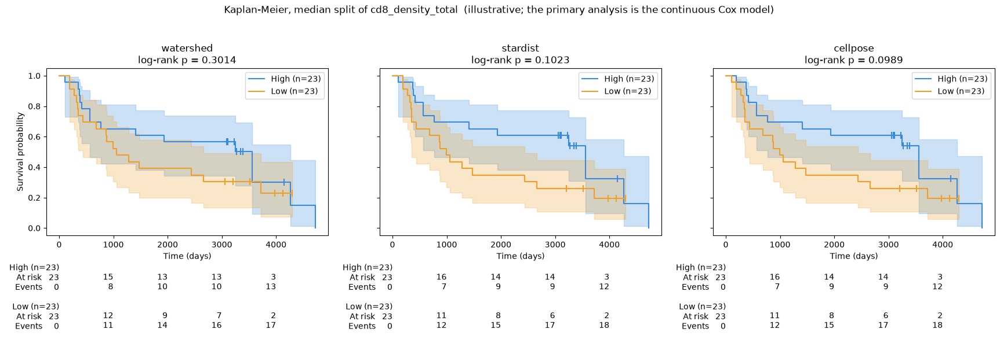

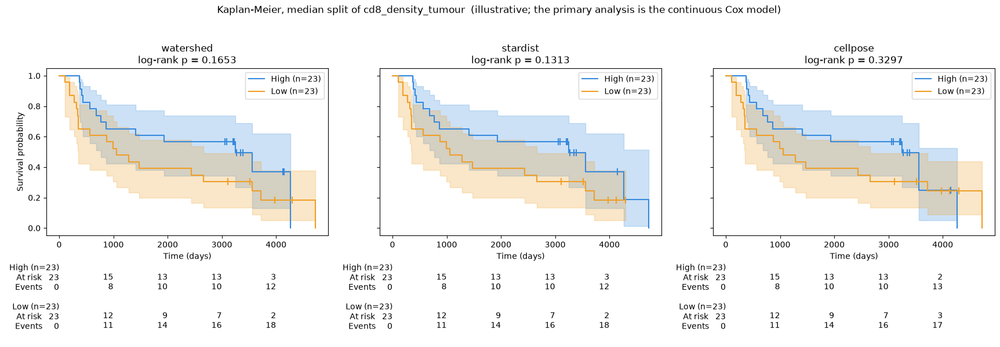

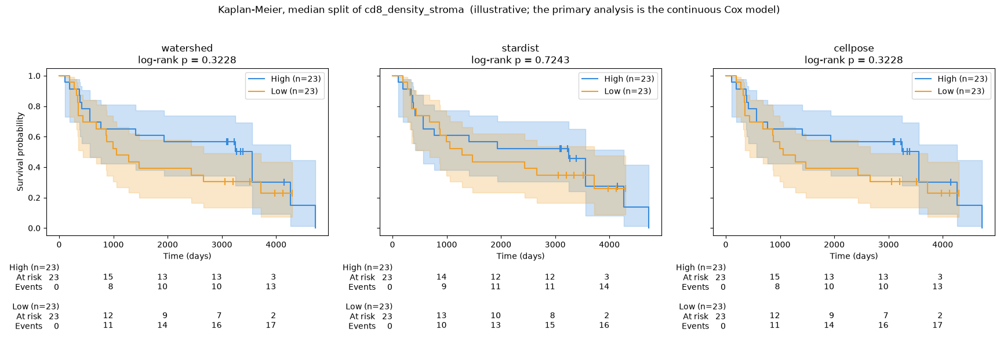

In [28]:
from lifelines.plotting import add_at_risk_counts

def km_grid(tables, exposure):
    methods = list(tables)
    fig, axes = plt.subplots(1, len(methods), figsize=(5.8 * len(methods), 6), sharey=True, squeeze=False)
    for ax, m in zip(axes[0], methods):
        d = exposure_columns(add_survival_columns(tables[m]), exposure)
        fitters = []
        for name, g, col in [('High', d[d.high == 1], '#378ADD'), ('Low', d[d.high == 0], '#EF9F27')]:
            kmf = KaplanMeierFitter().fit(g['time'], g['event'], label=f'{name} (n={len(g)})')
            kmf.plot_survival_function(ax=ax, ci_show=True, color=col, show_censors=True,
                                       censor_styles={'marker': '|', 'ms': 9, 'mew': 1.5})
            fitters.append(kmf)
        p = logrank_test(d.loc[d.high == 1, 'time'], d.loc[d.high == 0, 'time'],
                         d.loc[d.high == 1, 'event'], d.loc[d.high == 0, 'event']).p_value
        ax.set_title(f'{m}\nlog-rank p = {p:.4f}'); ax.set_xlabel('Time (days)')
        add_at_risk_counts(*fitters, ax=ax, rows_to_show=['At risk', 'Events'])
    axes[0][0].set_ylabel('Survival probability')
    fig.suptitle(f'Kaplan-Meier, median split of {exposure}  (illustrative; the primary analysis is the continuous Cox model)', y=1.03)
    plt.tight_layout(); plt.show()

for e in EXPOSURES:
    km_grid(tables, e)

In [29]:
for m in tables:
    d = exposure_columns(add_survival_columns(tables[m]), PRIMARY_EXPOSURE)
    for name, g in [('High', d[d.high == 1]), ('Low', d[d.high == 0])]:
        k = KaplanMeierFitter().fit(g['time'], g['event'])
        print(f"{m:10s} {name:4s} KM median survival: {k.median_survival_time_:7.0f} days | 5-year (1825 d) survival: {float(k.predict(1825)):.2f}")

watershed  High KM median survival:    3556 days | 5-year (1825 d) survival: 0.61
watershed  Low  KM median survival:    1053 days | 5-year (1825 d) survival: 0.39
stardist   High KM median survival:    3556 days | 5-year (1825 d) survival: 0.65
stardist   Low  KM median survival:     997 days | 5-year (1825 d) survival: 0.35
cellpose   High KM median survival:    3556 days | 5-year (1825 d) survival: 0.65
cellpose   Low  KM median survival:     997 days | 5-year (1825 d) survival: 0.35


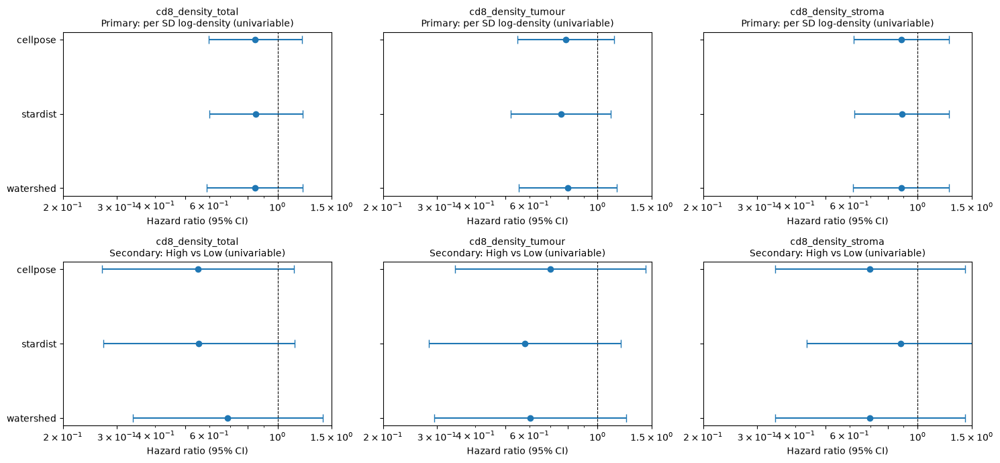

In [30]:
# Forest-style comparison of the hazard ratios across methods
fig, axes = plt.subplots(2, len(EXPOSURES), figsize=(5 * len(EXPOSURES), 7), squeeze=False, sharey=True)
for j, e in enumerate(EXPOSURES):
    sub = results_df[results_df.exposure == e].reset_index(drop=True)
    for i, (key, title) in enumerate([('cont_uni', 'Primary: per SD log-density (univariable)'), ('high_uni', 'Secondary: High vs Low (univariable)')]):
        ax = axes[i, j]
        y = np.arange(len(sub))
        hr, lo, hi = sub[f'HR_{key}'], sub[f'HR_{key}_lo'], sub[f'HR_{key}_hi']
        ax.errorbar(hr, y, xerr=[hr - lo, hi - hr], fmt='o', capsize=4)
        ax.axvline(1, color='k', ls='--', lw=.8); ax.set_xscale('log')
        ax.set_yticks(y); ax.set_yticklabels(sub.method); ax.invert_yaxis()
        ax.set_title(f'{e}\n{title}', fontsize=10); ax.set_xlabel('Hazard ratio (95% CI)')
        ax.set_xlim(0.2, 1.5)
        ax.set_xticks([0.2, 0.3, 0.5, 0.8, 1.0, 1.5])
plt.tight_layout(); plt.show()

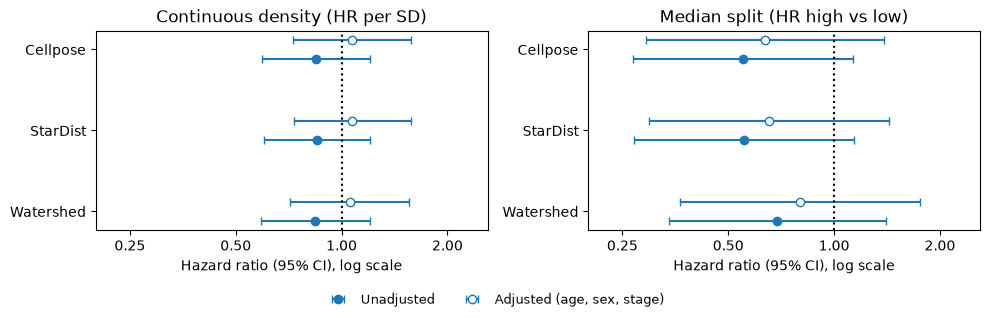

In [32]:
from matplotlib.ticker import ScalarFormatter

res = pd.read_csv("report_tables/otsu_in_tissue_min4000_open6/survival_results.csv")
res = res[res.exposure == "cd8_density_total"].set_index("method").loc[["watershed", "stardist", "cellpose"]]
NAMES = {"watershed": "Watershed", "stardist": "StarDist", "cellpose": "Cellpose"}

def forest(ax, stem, title):
    ys = np.arange(len(res))
    for dy, suffix, filled, label in [(-0.12, "uni", True, "Unadjusted"),
                                      (0.12, "multi", False, "Adjusted (age, sex, stage)")]:
        c = f"{stem}_{suffix}"
        hr, lo, hi = res[c].values, res[c + "_lo"].values, res[c + "_hi"].values
        ax.errorbar(hr, ys + dy, xerr=[hr - lo, hi - hr], fmt="o", color="tab:blue",
                    mfc="tab:blue" if filled else "white", capsize=3, label=label)
    ax.axvline(1, ls=":", color="k")
    ax.set_xscale("log"); ax.set_xlim(0.2, 2.6)
    ax.set_xticks([0.25, 0.5, 1, 2]); ax.xaxis.set_major_formatter(ScalarFormatter()); ax.minorticks_off()
    ax.set_yticks(ys); ax.set_yticklabels([NAMES[m] for m in res.index])
    ax.set_xlabel("Hazard ratio (95% CI), log scale"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
forest(axes[0], "HR_cont", "Continuous density (HR per SD)")
forest(axes[1], "HR_high", "Median split (HR high vs low)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

In [33]:
# How informative is this cohort? (Schoenfeld-type approximations, two-sided alpha = 0.05, 80% power)
from scipy.stats import norm
prim = results_df[results_df.exposure == PRIMARY_EXPOSURE]
d_events = int(prim['events'].iloc[0])
z_a, z_b = norm.ppf(0.975), norm.ppf(0.80)
hr_cont = np.exp((z_a + z_b) / np.sqrt(d_events))
hr_bin = np.exp(2 * (z_a + z_b) / np.sqrt(d_events))
print(f"{d_events} events. Smallest effect detectable with 80% power:")
print(f"  PRIMARY (continuous, per 1 SD of log-density): HR = {1 / hr_cont:.2f} (or {hr_cont:.2f})")
print(f"  secondary (median split, 1:1 groups):          HR = {1 / hr_bin:.2f} (or {hr_bin:.2f})")
for _, r in prim.iterrows():
    lc = abs(np.log(r['HR_cont_uni']))
    pw = norm.cdf(lc * np.sqrt(d_events) - z_a)
    need = (z_a + z_b) ** 2 / lc ** 2
    print(f"  {r['method']:10s} observed HR per SD {r['HR_cont_uni']:.2f}: power = {pw:.0%}; events needed for 80% power ~ {need:.0f}")

32 events. Smallest effect detectable with 80% power:
  PRIMARY (continuous, per 1 SD of log-density): HR = 0.61 (or 1.64)
  secondary (median split, 1:1 groups):          HR = 0.37 (or 2.69)
  watershed  observed HR per SD 0.84: power = 16%; events needed for 80% power ~ 268
  stardist   observed HR per SD 0.85: power = 15%; events needed for 80% power ~ 301
  cellpose   observed HR per SD 0.85: power = 15%; events needed for 80% power ~ 283


### 9.1 Are the differences between methods larger than sampling noise?


In [34]:
def bootstrap_logHR(tables, exposure, B=N_BOOT, seed=0):
    prepared = {}
    for m, t in tables.items():
        d = add_survival_columns(t).dropna(subset=['time', exposure])
        prepared[m] = d.set_index(KEY)
    common = sorted(set.intersection(*[set(d.index) for d in prepared.values()]))
    data = {}
    for m, d in prepared.items():
        d = d.loc[common]
        lx = np.log1p(d[exposure].to_numpy())
        data[m] = dict(t=d['time'].to_numpy(float), e=d['event'].to_numpy(int), x=d[exposure].to_numpy(float),
                       lx=lx, sd=lx.std(ddof=1))

    def fit(t, e, x):
        if e.sum() == 0 or np.ptp(x) == 0:
            return np.nan
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                cph = CoxPHFitter().fit(pd.DataFrame({'time': t, 'event': e, 'x': x}), 'time', 'event')
            return float(cph.params_['x'])
        except Exception:
            return np.nan

    rng = np.random.default_rng(seed)
    n = len(common)
    bb = {m: [] for m in data}; bc = {m: [] for m in data}
    for _ in range(B):
        idx = rng.integers(0, n, n)
        for m, v in data.items():
            xi = v['x'][idx]
            bb[m].append(fit(v['t'][idx], v['e'][idx], (xi >= np.median(xi)).astype(float)))
            bc[m].append(fit(v['t'][idx], v['e'][idx], v['lx'][idx] / v['sd']))
    full = {m: (fit(v['t'], v['e'], (v['x'] >= np.median(v['x'])).astype(float)),
                fit(v['t'], v['e'], v['lx'] / v['sd'])) for m, v in data.items()}
    return pd.DataFrame(bb), pd.DataFrame(bc), full, n

def summarise_bootstrap(boot_bin, boot_cont, full, n, exposure):
    rows = []
    for label, boot, k in [('per SD log-density (PRIMARY)', boot_cont, 1), ('High vs Low (secondary)', boot_bin, 0)]:
        for m in boot.columns:
            lo, hi = np.nanpercentile(boot[m], [2.5, 97.5])
            rows.append({'exposure': exposure, 'effect': label, 'comparison': m, 'n': n,
                         'HR (full sample)': np.exp(full[m][k]), 'HR boot 95% interval': f"{np.exp(lo):.2f} - {np.exp(hi):.2f}"})
        for a, b in itertools.combinations(boot.columns, 2):
            diff = (boot[a] - boot[b]).dropna()
            lo, hi = np.percentile(diff, [2.5, 97.5])
            rows.append({'exposure': exposure, 'effect': label, 'comparison': f'{a} - {b} (difference in log HR)', 'n': n,
                         'HR (full sample)': np.nan,
                         'HR boot 95% interval': f"{diff.mean():+.3f}  [{lo:+.3f}, {hi:+.3f}]"})
    return pd.DataFrame(rows)

boot_out = {}
boot_tables = []
for e in EXPOSURES:
    bb, bc, full, n_common = bootstrap_logHR(tables, e)
    boot_out[e] = (bb, bc)
    boot_tables.append(summarise_bootstrap(bb, bc, full, n_common, e))
display(pd.concat(boot_tables, ignore_index=True))

,exposure,effect,comparison,n,HR (full sample),HR boot 95% interval
0,cd8_density_total,per SD log-density (PRIMARY),watershed,46,0.842596,0.62 - 1.17
1,cd8_density_total,per SD log-density (PRIMARY),stardist,46,0.850826,0.63 - 1.16
2,cd8_density_total,per SD log-density (PRIMARY),cellpose,46,0.846666,0.62 - 1.15
3,cd8_density_total,per SD log-density (PRIMARY),watershed - stardist (difference in log HR),46,NaN,"-0.010 [-0.050, +0.029]"
4,cd8_density_total,per SD log-density (PRIMARY),watershed - cellpose (difference in log HR),46,NaN,"-0.004 [-0.041, +0.037]"
5,cd8_density_total,per SD log-density (PRIMARY),stardist - cellpose (difference in log HR),46,NaN,"+0.005 [-0.017, +0.030]"
6,cd8_density_total,High vs Low (secondary),watershed,46,0.688854,0.31 - 1.42
7,cd8_density_total,High vs Low (secondary),stardist,46,0.554142,0.28 - 1.38
8,cd8_density_total,High vs Low (secondary),cellpose,46,0.551065,0.27 - 1.35
9,cd8_density_total,High vs Low (secondary),watershed - stardist (difference in log HR),46,NaN,"+0.109 [-0.052, +0.621]"


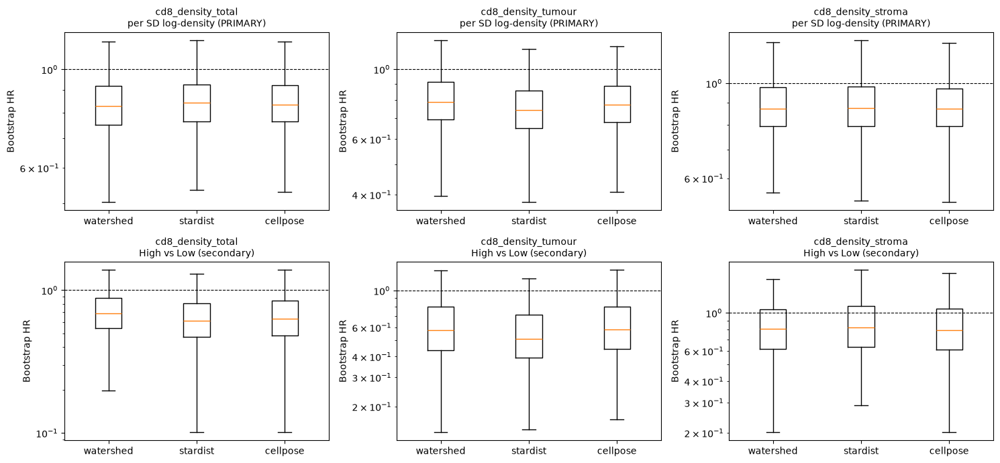

In [35]:
fig, axes = plt.subplots(2, len(EXPOSURES), figsize=(5 * len(EXPOSURES), 7), squeeze=False)
for j, e in enumerate(EXPOSURES):
    for i, (boot, title) in enumerate(zip(boot_out[e][::-1], ['per SD log-density (PRIMARY)', 'High vs Low (secondary)'])):
        ax = axes[i, j]
        data, names = [np.exp(boot[m].dropna()) for m in boot.columns], list(boot.columns)
        try:
            ax.boxplot(data, tick_labels=names, showfliers=False)      # matplotlib >= 3.9
        except TypeError:
            ax.boxplot(data, labels=names, showfliers=False)
        ax.axhline(1, color='k', ls='--', lw=.8)
        ax.set_yscale('log'); ax.set_ylabel('Bootstrap HR'); ax.set_title(f'{e}\n{title}', fontsize=10)
plt.tight_layout(); plt.show()

### 9.2 Model checks for the primary exposure

Proportional-hazards test (smallest p-value across covariates; a small p suggests the PH assumption is
questionable for that covariate) and the full multivariable table for each method.

In [36]:
for m in tables:
    key = (PRIMARY_EXPOSURE, m)
    if key not in cox_models:
        continue
    cph, x = cox_models[key]
    ph = proportional_hazard_test(cph, x, time_transform='rank').summary
    worst = ph['p'].idxmin()
    print(f"\n===== {m} | {PRIMARY_EXPOSURE} (per SD log-density, adjusted) | PH test: smallest p = {ph.loc[worst, 'p']:.3f} ({worst}) =====")
    print(cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].round(3).to_string())


===== watershed | cd8_density_total (per SD log-density, adjusted) | PH test: smallest p = 0.102 (Age) =====
                              exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                               
log_z                             1.054                0.715                1.554  0.789
Age                               1.013                0.961                1.066  0.639
Sex_Male                          2.970                1.382                6.383  0.005
stage_group_Early                 0.222                0.075                0.659  0.007
stage_group_Locally advanced      0.262                0.083                0.831  0.023

===== stardist | cd8_density_total (per SD log-density, adjusted) | PH test: smallest p = 0.097 (Age) =====
                              exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                            

### 9.3 Investigating the Performance-status hazard ratio

dtype: int64
Raw values (including missing):
Performance status
0    28
1    18
non-numeric or missing after conversion: 0 of 46


,patients,deaths,% dead,KM median survival (days)
ps,,,,
0,28,20,71.4,1408.0
1,18,12,66.7,3249.0



Univariable, per unit of PS: HR 0.71 (0.33-1.53), p = 0.382
Univariable, each level vs lowest level:
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                            
PS_1           0.712                0.332                1.525  0.382


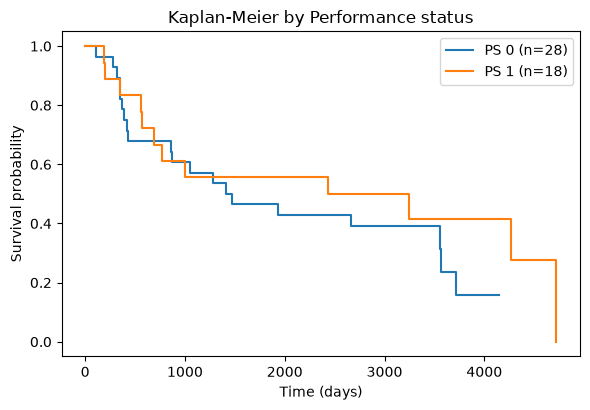


Performance status vs Stage group:


stage_group,Advanced,Early,Locally advanced
ps,,,
0,4,17,7
1,4,9,5


Performance status vs Sex:


Sex,Female,Male
ps,,
0,17,11
1,8,10


PS HR with nothing else + CD8 density: 0.71 (0.33-1.52), p = 0.379  [n=46, events=32]
PS HR with ['Age', 'Sex'] + CD8 density: 0.60 (0.27-1.31), p = 0.196  [n=46, events=32]
PS HR with ['Age', 'Sex', 'Stage'] + CD8 density: 0.53 (0.23-1.24), p = 0.143  [n=46, events=32]


In [37]:
ps_col = 'Performance status'
base = add_survival_columns(tables[cohort_methods[0]])
print("dtype:", base[ps_col].dtype)
print("Raw values (including missing):")
print(base[ps_col].value_counts(dropna=False).sort_index().to_string())
base = base.assign(ps=pd.to_numeric(base[ps_col], errors='coerce'))
print("non-numeric or missing after conversion:", int(base['ps'].isna().sum()), "of", len(base))
base = base.dropna(subset=['ps', 'time'])

by = base.groupby('ps').agg(patients=('event', 'size'), deaths=('event', 'sum'))
by['% dead'] = 100 * by['deaths'] / by['patients']
by['KM median survival (days)'] = [KaplanMeierFitter().fit(base.loc[base.ps == lv, 'time'], base.loc[base.ps == lv, 'event']).median_survival_time_
                                   for lv in by.index]
display(by.round(1))
sparse = by.index[by['patients'] < 5].tolist()
if sparse:
    print(f"WARNING: levels {sparse} have fewer than 5 patients: any HR involving them is very unstable.")

# univariable: numeric (per unit) and categorical (each level vs the lowest)
u = CoxPHFitter().fit(base[['time', 'event', 'ps']], 'time', 'event').summary.loc['ps']
print(f"\nUnivariable, per unit of PS: HR {u['exp(coef)']:.2f} ({u['exp(coef) lower 95%']:.2f}-{u['exp(coef) upper 95%']:.2f}), p = {u['p']:.3f}")
cat = pd.get_dummies(base['ps'], prefix='PS', drop_first=True, dtype=float)
try:
    cs_ = CoxPHFitter().fit(pd.concat([base[['time', 'event']], cat], axis=1), 'time', 'event').summary
    print("Univariable, each level vs lowest level:")
    print(cs_[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].round(3).to_string())
except Exception as e:
    print("categorical model failed (probably too few patients in a level):", e)

# Kaplan-Meier by level
levels = sorted(base['ps'].unique())
if 2 <= len(levels) <= 6:
    fig, ax = plt.subplots(figsize=(6, 4.2))
    for lv in levels:
        g = base[base['ps'] == lv]
        KaplanMeierFitter().fit(g['time'], g['event'], label=f'PS {lv:g} (n={len(g)})').plot_survival_function(ax=ax, ci_show=False)
    ax.set_xlabel('Time (days)'); ax.set_ylabel('Survival probability'); ax.set_title('Kaplan-Meier by Performance status')
    plt.tight_layout(); plt.show()

# overlap with Stage / Sex
base['stage_group'] = base['Stage'].astype(str).str.strip().map(STAGE_MAP)
print("\nPerformance status vs Stage group:");  display(pd.crosstab(base['ps'], base['stage_group']))
print("Performance status vs Sex:");           display(pd.crosstab(base['ps'], base['Sex']))

# does the PS hazard ratio depend on the other covariates?
dd = exposure_columns(add_survival_columns(tables[cohort_methods[0]]), PRIMARY_EXPOSURE)
for covs in [['Performance status'], ['Age', 'Sex', 'Performance status'], ['Age', 'Sex', 'Stage', 'Performance status']]:
    try:
        c_, x_, info_ = fit_multivariable(dd, 'log_z', covs)
        s_ = c_.summary.loc['Performance status']
        print(f"PS HR with {covs[:-1] or 'nothing else'} + CD8 density: {s_['exp(coef)']:.2f} "
              f"({s_['exp(coef) lower 95%']:.2f}-{s_['exp(coef) upper 95%']:.2f}), p = {s_['p']:.3f}  [n={info_['n']}, events={info_['events']}]")
    except Exception as e:
        print(covs, "failed:", e)

### 9.4 Sensitivity of the CD8 call (ring size, overlap fraction, intensity threshold)

  10/73 cores (61s)
  20/73 cores (125s)
  30/73 cores (184s)
  40/73 cores (245s)
  50/73 cores (307s)
  60/73 cores (368s)
  70/73 cores (427s)
  73/73 cores (445s)
Baseline reproduces the main analysis: True


,setting,% CD8+ cells,median density,Spearman vs baseline,patients switching High/Low,HR per SD,p (per SD),C-index,HR High vs Low (secondary)
0,baseline,7.171,262.836,1.000,0,0.851,0.365,0.552,0.554
1,ring 4 px (2 um),7.566,279.342,0.995,0,0.861,0.400,0.549,0.554
2,ring 8 px (4 um),6.776,242.029,0.997,2,0.840,0.328,0.555,0.700
3,overlap > 0.3,10.774,410.920,0.995,0,0.841,0.329,0.551,0.554
4,overlap > 0.7,5.062,182.958,0.991,4,0.829,0.305,0.560,0.689
5,CD8 threshold 100,9.257,324.482,0.989,0,0.852,0.366,0.547,0.554
6,CD8 threshold 200,6.100,225.855,0.995,2,0.834,0.316,0.565,0.551


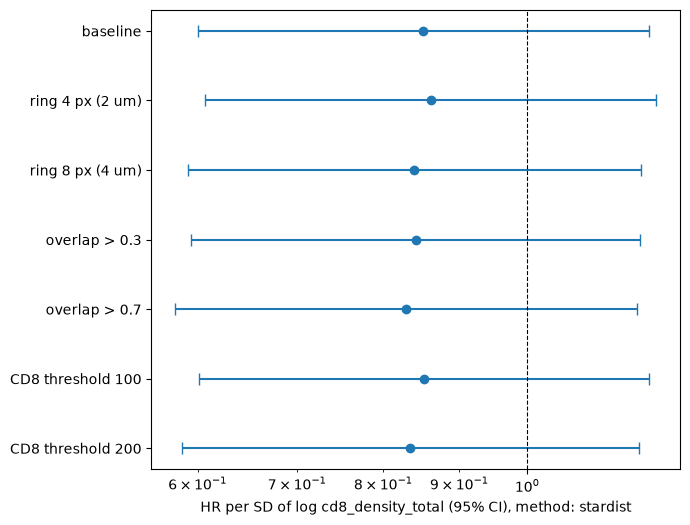

In [38]:
if not RUN_CD8_SENSITIVITY:
    print("Skipped (RUN_CD8_SENSITIVITY = False)")
else:
    from scipy.stats import spearmanr
    base = dict(ring=RING_DISTANCE, overlap=CD8_OVERLAP_THRESHOLD, thr=CD8_THRESHOLD)
    settings = [dict(base, label='baseline')]
    settings += [dict(base, ring=r, label=f"ring {r} px ({r * PIXEL_SIZE_UM:g} um)") for r in SENS_RINGS if r != base['ring']]
    settings += [dict(base, overlap=o, label=f"overlap > {o:g}") for o in SENS_OVERLAPS if o != base['overlap']]
    settings += [dict(base, thr=t, label=f"CD8 threshold {t}") for t in SENS_THRESHOLDS if t != base['thr']]
    m_s = SENS_METHOD if SENS_METHOD in cohort_methods else cohort_methods[0]
    files = [f for f in file_list if sample_names[f] in cohort_cores]
    rings = sorted({s_['ring'] for s_ in settings}); thrs = sorted({s_['thr'] for s_ in settings})
    rows = [[] for _ in settings]
    t0 = time.time()
    for k, f in enumerate(files, 1):
        sn = sample_names[f]
        masks = get_masks(f)
        cells = cells_store[m_s][sn]
        nuclei = load_seg(m_s, f).astype(np.int64)
        n = int(nuclei.max())
        cd8_img = load_image(f)[:, :, CD8_CHANNEL]
        cd8_masks = {t: make_cd8_mask(cd8_img, t) for t in thrs}
        ring_lab = {}
        for r in rings:
            flat = np.where(nuclei > 0, 0, expand_labels(nuclei, distance=r)).ravel().astype(np.int64)
            ring_lab[r] = (flat, np.bincount(flat, minlength=n + 1))
        comp = np.empty(n + 1, dtype=object)
        comp[cells['label'].to_numpy()] = cells['compartment'].to_numpy()
        summary = summarise_core(cells, masks)
        hits = {}
        for i, s_ in enumerate(settings):
            flat, area = ring_lab[s_['ring']]
            key = (s_['ring'], s_['thr'])
            if key not in hits:
                hits[key] = np.bincount(flat, weights=cd8_masks[s_['thr']].ravel().astype(np.float64), minlength=n + 1)
            pos = (hits[key] / np.maximum(area, 1) > s_['overlap']) & (area > 0)
            pos[0] = False
            row = dict(summary, sample_name=sn)
            row['n_cd8_tumour'] = int((pos & (comp == 'Tumour')).sum())
            row['n_cd8_stroma'] = int((pos & (comp == 'Stroma')).sum())
            rows[i].append(row)
        if k % 10 == 0 or k == len(files):
            print(f"  {k}/{len(files)} cores ({time.time() - t0:.0f}s)")

    ref = core_summary[m_s].set_index('sample_name')
    b0 = pd.DataFrame(rows[0]).set_index('sample_name')
    same = (b0[['n_cd8_tumour', 'n_cd8_stroma']] == ref.loc[b0.index, ['n_cd8_tumour', 'n_cd8_stroma']]).all().all()
    print("Baseline reproduces the main analysis:", bool(same))

    out, base_density = [], None
    for s_, r_ in zip(settings, rows):
        cs = pd.DataFrame(r_)
        tab = make_patient_table(cs, clinical_df)
        d = exposure_columns(add_survival_columns(tab), PRIMARY_EXPOSURE)
        uc, ub = cox_univariable(d, 'log_z'), cox_univariable(d, 'high')
        dens = tab.set_index(KEY)[PRIMARY_EXPOSURE]
        if base_density is None:
            base_density = dens
        both = pd.concat([base_density, dens], axis=1, keys=['b', 'c']).dropna()
        out.append({'setting': s_['label'],
                    '% CD8+ cells': 100 * (cs.n_cd8_tumour.sum() + cs.n_cd8_stroma.sum()) / (cs.n_cells_tumour.sum() + cs.n_cells_stroma.sum()),
                    'median density': dens.median(),
                    'Spearman vs baseline': spearmanr(both['b'], both['c'])[0],
                    'patients switching High/Low': int(((both['b'] >= both['b'].median()) != (both['c'] >= both['c'].median())).sum()),
                    'HR per SD': uc['HR'], 'lo': uc['lo'], 'hi': uc['hi'], 'p (per SD)': uc['p'], 'C-index': uc['cindex'],
                    'HR High vs Low (secondary)': ub['HR']})
    sens_df = pd.DataFrame(out)
    display(sens_df.drop(columns=['lo', 'hi']).round(3))

    fig, ax = plt.subplots(figsize=(7, 0.55 * len(sens_df) + 1.5))
    y = np.arange(len(sens_df))
    ax.errorbar(sens_df['HR per SD'], y, xerr=[sens_df['HR per SD'] - sens_df['lo'], sens_df['hi'] - sens_df['HR per SD']], fmt='o', capsize=4)
    ax.axvline(1, color='k', ls='--', lw=.8); ax.set_xscale('log')
    ax.set_yticks(y); ax.set_yticklabels(sens_df['setting']); ax.invert_yaxis()
    ax.set_xlabel(f'HR per SD of log {PRIMARY_EXPOSURE} (95% CI), method: {m_s}')
    plt.tight_layout(); plt.show()

## 10. Export the tables for the report

In [40]:
import skimage

def get_cellpose_config():
    path = os.path.join(CELLPOSE_DIR, "run_config.json")
    if runner_ready(CELLPOSE_PYTHON, CELLPOSE_RUNNER, 'Cellpose'):
        cmd = [CELLPOSE_PYTHON, CELLPOSE_RUNNER, "--write-config", path, "--batch-size", str(CELLPOSE_BATCH_SIZE)]
        if CELLPOSE_DIAMETER:
            cmd += ["--diameter", str(CELLPOSE_DIAMETER)]
        env = os.environ.copy(); env["MPLBACKEND"] = "Agg"
        r = subprocess.run(cmd, capture_output=True, text=True, env=env, timeout=900)
        if r.returncode != 0:
            print("Could not query Cellpose:", (r.stderr.strip().splitlines() or ['no output'])[-1])
    return read_json(path, {})

methods_config = {
    'pixel_size_um': PIXEL_SIZE_UM,
    'watershed': {**WS_PARAMS, 'software': f'scikit-image {skimage.__version__}', 'threshold': 'global Otsu on the Gaussian-smoothed DAPI channel'},
    'stardist': dict(STARDIST_CONFIG),
    'cellpose': get_cellpose_config(),
    'downstream_masks_and_phenotyping': {**MASK_PARAMS, **CLASSIFY_PARAMS},
}

print("WATERSHED :", methods_config['watershed'])
print("\nSTARDIST  :", methods_config['stardist'])
unfilled = [k for k, v in STARDIST_CONFIG.items() if isinstance(v, str) and 'FILL_IN' in v]
if unfilled:
    print(f"   *** still to fill in from your StarDist runner: {unfilled}")
cp = methods_config['cellpose']
if cp:
    print(f"\nCELLPOSE  : v{cp.get('cellpose_version')} | torch {cp.get('torch_version')} | {cp.get('device')}")
    print("   model            :", cp.get('model_selection'), '|', cp.get('pretrained_model'))
    print("   explicit settings:", cp.get('explicit_eval_settings'))
    print("   all settings used:", cp.get('all_eval_settings_used'))
else:
    print("\nCELLPOSE  : configuration unavailable (check CELLPOSE_PYTHON / CELLPOSE_RUNNER in Section 1)")

WATERSHED : {'sigma': 1, 'hole_area': 100, 'disk_size': 1, 'min_obj': 70, 'min_dist': 5, 'min_final': 50, 'software': 'scikit-image 0.26.0', 'threshold': 'global Otsu on the Gaussian-smoothed DAPI channel'}

STARDIST  : {'model': '2D_versatile_fluo (pretrained, StarDist2D.from_pretrained)', 'prob_thresh': None, 'nms_thresh': None, 'normalization': 'csbdeep.utils.normalize(dapi), defaults pmin=3, pmax=99.8, axis=None (whole image, i.e. per image), no clipping, float32', 'tiling': 'n_tiles not passed to predict_instances (default n_tiles=None)', 'input': 'DAPI channel only (index 2), whole image, 2D', 'postprocessing': 'none: labels saved exactly as returned by predict_instances', 'versions': 'stardist 0.9.2, csbdeep 0.8.2, tensorflow 2.21.0', 'runner_script': './stardist_runner_batch.py'}

CELLPOSE  : v4.2.1.1 | torch 2.5.1+cu121 | NVIDIA GeForce GTX 1050 with Max-Q Design
   model            : library default pretrained model (Cellpose-SAM family) | /home/mar-a/.cellpose/models/cpsam_v

In [41]:
# One sub-folder per tumour-mask setting, so experiments with different masks never overwrite each other
tag = TUMOUR_THRESHOLD_MODE + (f"_{TUMOUR_CK_FIXED:g}" if TUMOUR_THRESHOLD_MODE == 'fixed' else "")
out_dir = os.path.join("report_tables", f"{tag}_min{TUMOUR_MIN_AREA}_open{TUMOUR_OPEN_RADIUS}")
os.makedirs(out_dir, exist_ok=True)
seg_table.to_csv(os.path.join(out_dir, "segmentation_summary.csv"))
results_df.to_csv(os.path.join(out_dir, "survival_results.csv"), index=False)
pd.concat(boot_tables, ignore_index=True).to_csv(os.path.join(out_dir, "bootstrap_hr_differences.csv"), index=False)
if 'agree_df' in globals():
    agree_df.to_csv(os.path.join(out_dir, "density_agreement.csv"), index=False)
for m, t in tables.items():
    t.to_csv(os.path.join(out_dir, f"patient_table_{m}.csv"), index=False)
write_json(os.path.join(out_dir, "methods_configuration.json"), methods_config)
if 'sens_df' in globals():
    sens_df.to_csv(os.path.join(out_dir, "cd8_call_sensitivity.csv"), index=False)
if 'ev' in globals():
    ev.to_csv(os.path.join(out_dir, "annotation_detection_per_window.csv"), index=False)
print("written to", out_dir, ":", sorted(os.listdir(out_dir)))

written to report_tables/otsu_in_tissue_min4000_open6 : ['bootstrap_hr_differences.csv', 'cd8_call_sensitivity.csv', 'density_agreement.csv', 'methods_configuration.json', 'patient_table_cellpose.csv', 'patient_table_stardist.csv', 'patient_table_watershed.csv', 'segmentation_summary.csv', 'survival_results.csv']
